[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/11_dpgmm.py)

# Dirichlet Process Gaussian Mixtures: Stick-Breaking and Gibbs Sampling

`tgmm.GaussianMixture`'s Gibbs-sampling mode (`n_components=None`) infers the effective number of mixture components from the data, rather than requiring it fixed in advance, via collapsed Gibbs sampling (Neal's Algorithm 3) -- either truncated at `max_components`, or fully unbounded. This notebook first explains the mathematics (stick-breaking, the concentration parameter, the Chinese Restaurant Process), then watches the sampler work step by step, and finally validates it against classical EM at scale.

**What you'll learn**

1. the underlying math -- the stick-breaking construction, its concentration parameter $\alpha$, and the Chinese Restaurant Process view that Gibbs sampling relies on -- with a runnable visualization of each piece (the NIW prior parameters that plug into this are introduced in [09 -- Priors](09_priors.ipynb); here we only cover how Gibbs sampling *uses* them),
2. how to read a Gibbs run: hard cluster assignments and the active component count evolving sweep by sweep, and why truncated and unbounded Gibbs agree when seeded from the same starting partition,
3. how it compares at scale: synthetic 10-dimensional data at three true cluster counts (5, 10, 20), comparing a classical `GaussianMixture` (K chosen by minimum BIC over a `K=1..30` sweep) against truncated and unbounded Gibbs-mode `GaussianMixture` on well-separated data, on genuinely overlapping clusters, and on overlapping *non-Gaussian* cluster shapes -- to see what happens when the Gaussian-component assumption itself is wrong.

All plotting goes through the library's official [`plot_gmm`](03_visualise.ipynb) tooling, projecting the 10-d Gaussians to 2D via PCA for visualization only -- the sampler itself never sees that projection.

**Prerequisites:** [02 -- EM Algorithm](02_em_algorithm.ipynb), [03 -- Visualization](03_visualise.ipynb), [09 -- Priors](09_priors.ipynb).
See also the [Gaussian Mixture Model user guide](../user-guide/gaussian-mixture.md#gibbs-sampling-inferring-the-number-of-components).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import time, math, warnings
from types import SimpleNamespace

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from tgmm import GaussianMixture, plot_gmm, dynamic_figsize
from tgmm.synthetic_data import generate_gmm_data

device = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

torch.set_default_dtype(torch.float64)
# marimo embeds figures at 2 x figure.dpi, and tgmm's plot theme sets figure.dpi=300: the 12-panel
# comparison figures below would then exceed marimo's output size limit, so use a lower resolution.
plt.rcParams['figure.dpi'] = 60

## 1. The mathematics of a Dirichlet Process Gaussian mixture

### From finite to infinite mixtures

A standard finite GMM assumes a fixed $K$:

$$p(x) = \sum_{k=1}^K \pi_k \, \mathcal{N}(x \mid \mu_k, \Sigma_k), \qquad \sum_{k=1}^K \pi_k = 1,$$

with $K$ chosen in advance. A **Dirichlet Process (DP) mixture** instead
places a nonparametric prior over an *infinite* sequence of possible
components and lets the posterior decide how many of them the data actually
supports.

### Stick-breaking construction

Sethuraman's stick-breaking representation draws, for $k = 1, 2, \dots$:

$$v_k \sim \mathrm{Beta}(1, \alpha), \qquad \pi_k = v_k \prod_{j<k} (1 - v_j).$$

Picture a unit-length stick: $v_1$ breaks off the first piece $\pi_1$, then
$v_2$ breaks off a $v_2$ fraction of what remains, and so on. Since each
$v_j < 1$ almost surely, later pieces shrink geometrically in expectation, so
$\sum_k \pi_k = 1$ with probability 1 despite infinitely many terms. The
**concentration parameter** $\alpha$ controls how fast the stick is
consumed: small $\alpha$ front-loads mass onto the first few components
(favoring *fewer* effective clusters); large $\alpha$ spreads mass thinly
across many. The cell below draws one literal realization of the process for
a few values of $\alpha$, so you can see the effect directly rather than
just read the formula.

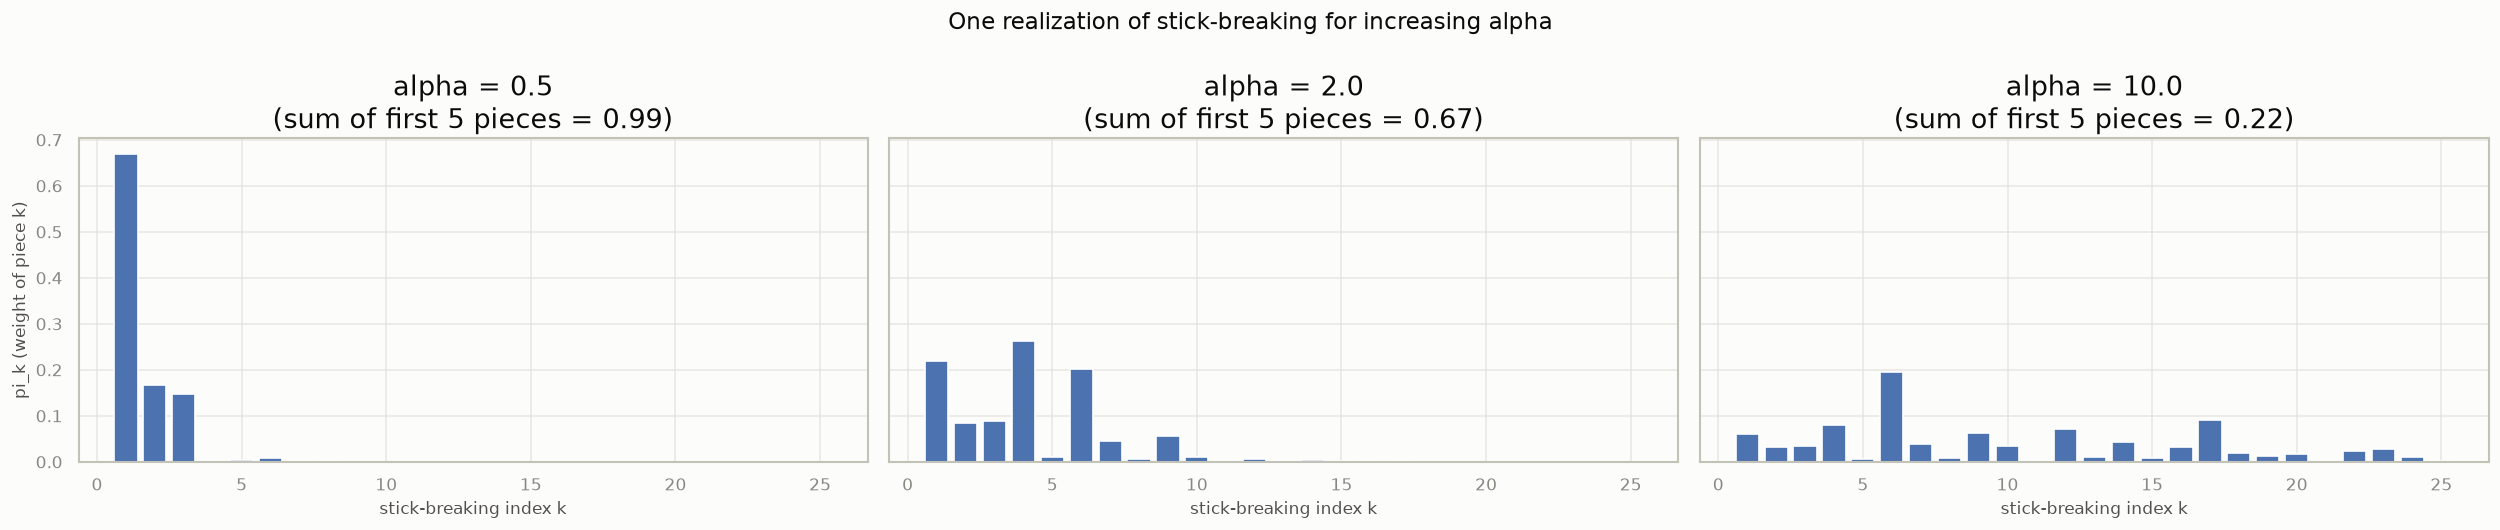

In [ ]:
def sample_stick_breaking(alpha, n_sticks=25, seed=0):
    rng = np.random.RandomState(seed)
    v = rng.beta(1.0, alpha, size=n_sticks)
    remaining = np.cumprod(np.concatenate([[1.0], 1 - v[:-1]]))
    pi = v * remaining
    return pi
_fig, _axes = plt.subplots(1, 3, figsize=dynamic_figsize(1, 3), sharey=True)
for _ax, alpha in zip(_axes, [0.5, 2.0, 10.0]):
    pi = sample_stick_breaking(alpha, n_sticks=25, seed=SEED)
    _ax.bar(np.arange(1, len(pi) + 1), pi, color='#4C72B0')
    _ax.set_title(f'alpha = {alpha}\n(sum of first 5 pieces = {pi[:5].sum():.2f})')
    _ax.set_xlabel('stick-breaking index k')
_axes[0].set_ylabel('pi_k (weight of piece k)')
_fig.suptitle('One realization of stick-breaking for increasing alpha', fontsize=14)
plt.tight_layout()
plt.gcf()

With $\alpha=0.5$, almost all of the stick is consumed by the first handful
of pieces -- an equivalent finite mixture would need very few components.
With $\alpha=10$, the first several pieces are all comparably small -- many
components share the mass. This is the mechanism `GaussianMixture`'s (Gibbs
mode) `alpha` constructor argument controls: it is a fixed hyperparameter
(not learned), and larger values favor discovering more components.

Each component also draws its own parameters from a base measure $G_0$ --
here the conjugate **Normal-Inverse-Wishart (NIW)** distribution:

$$\Sigma_k \sim \mathcal{IW}(\Psi_0, \nu_0), \qquad \mu_k \mid \Sigma_k \sim \mathcal{N}\!\left(\mu_0,\, \tfrac{1}{\lambda_0}\Sigma_k\right).$$

Data is generated as $z_i \sim \mathrm{Categorical}(\pi)$,
$x_i \mid z_i = k \sim \mathcal{N}(\mu_k, \Sigma_k)$. These NIW
hyperparameters $(\mu_0, \lambda_0, \Psi_0, \nu_0)$ are a **fixed prior**
-- either supplied, or resolved once from the data via `suggest_priors`
(prior mean = data mean, weak precision, `degrees_of_freedom_prior = d + 2`,
prior covariance = empirical covariance). Nothing about the prior is
learned; what Gibbs sampling infers, per component, every sweep, is the NIW
**posterior** $(\mu_n, \lambda_n, \nu_n, \Psi_n)$ given that fixed prior and
whichever points currently belong to the component. See
[`09_priors.ipynb`](09_priors.ipynb) for how these same NIW priors are
defined, visualized, and used for MAP estimation in the (finite, non-Gibbs)
case.

`GaussianMixture`'s Gibbs mode (`n_components=None`) fits this via Gibbs
sampling -- either letting components be created and destroyed on the fly
(`max_components=None`), or truncating the infinite sum at a fixed
`max_components` ($K_{\max}$) as a computational convenience.

### Gibbs sampling: the Chinese Restaurant Process

Marginalizing the infinitely many stick-breaking weights out analytically
gives an equivalent, fully exchangeable representation: the **Chinese
Restaurant Process (CRP)**. Customer $i$, walking into a restaurant of
customers already seated at tables $1, \dots, K$, sits at:

$$p(z_i = k \mid z_{-i}) \propto
\begin{cases}
n_k^{-i} & \text{existing table } k \\
\alpha & \text{a brand-new table}
\end{cases}$$

where $n_k^{-i}$ is the number of points currently at table $k$, excluding
$i$. Combined with the NIW conjugate prior, this is **Neal's (2000)
Algorithm 3**: since $(\mu_k, \Sigma_k)$ can be integrated out in closed
form, the likelihood term for an existing table is the NIW **posterior
predictive** -- a multivariate Student-$t$ distribution -- evaluated at
$x_i$ using only that table's other members; the likelihood for a new table
uses the same Student-$t$ predictive under the prior alone. This is exactly
what `GaussianMixture`'s Gibbs sampler resamples, one point at a time:
remove point $i$ from its current table, recompute every table's marginal
likelihood for $x_i$, weight existing tables by $n_k^{-i}$ and a
hypothetical new table by $\alpha$, then re-seat $i$ by sampling from these
(softmax-normalized) probabilities.

`max_components=None` (**unbounded**) runs this with no cap on the number of
tables: existing tables are scored by $\log n_k^{-i} + \text{marginal-lik}$,
a new table by $\log\alpha + \text{marginal-lik (prior alone)}$.

An integer `max_components=K` (**truncated**) instead fixes $K$ slots and
uses

$$p(z_i = k \mid z_{-i}) \propto \left(n_k^{-i} + \tfrac{\alpha}{K}\right) \cdot \text{marginal-lik}(x_i \mid \text{table } k),$$

the finite-dimensional Dirichlet-multinomial ("Polya urn") approximation to
the CRP -- exact for a symmetric $\mathrm{Dirichlet}(\alpha/K, \dots,
\alpha/K)$ prior over the $K$ weights, and converging to the untruncated CRP
rule above as $K$ grows relative to the number of clusters actually in use.
Because both rules are driven by the same occupancy counts $n_k$, given the
*same* starting point the two samplers agree exactly; differences that show
up later in this notebook when they're given *different* starting
truncation levels are a mixing/initialization effect (Gibbs samplers merge
components easily but split them only slowly), not a difference in the
underlying rule -- see [the DPGMM design doc](https://github.com/adriansousapoza/tgmm/blob/main/docs/superpowers/specs/2026-07-28-dpgmm-design.md)
for a worked check of this.

Unlike EM, Gibbs sampling has no notion of "responsibilities" or a
monotone-improving lower bound to watch converge -- instead, in the
walkthrough below, we watch **hard cluster assignments** change sweep by
sweep, and the **number of components** rise and fall as the sampler
explores, then settle.

## 2. Watching the sampler work: a step-by-step 10-d example

The same generative recipe used in Round 2 below (`true_k=10`,
`spread=4.0`, `d=10`) -- overlapping enough that some points sit genuinely
ambiguously between two generating Gaussians, giving both an "easy" part
(well-separated pairs) and a genuinely hard part (close pairs). Gibbs-mode
`GaussianMixture` fits directly in the full 10-d space; every plot below
shows data and predictions **projected to 2D via PCA** (fit once on this
dataset) purely for visualization -- the sampler itself never sees this
projection.

n_samples=600, true_k=10, d=10


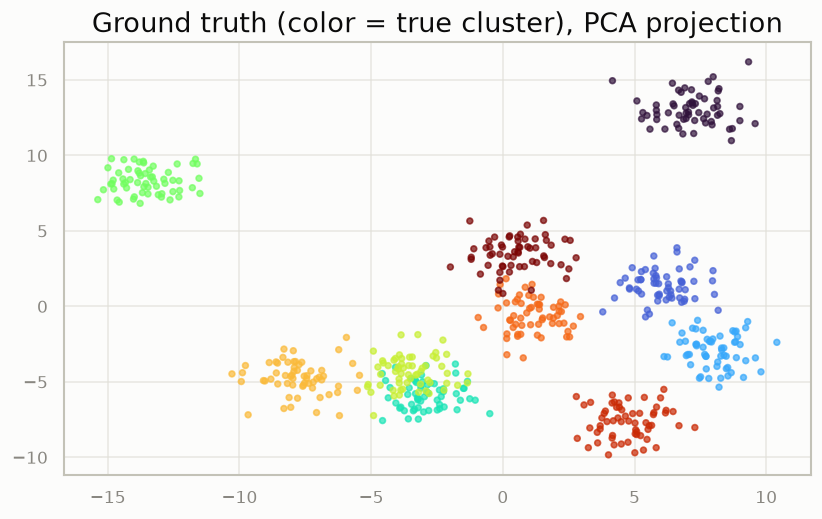

In [ ]:
def make_walkthrough_blobs(k, n_per_cluster, spread, d=10, seed=SEED):
    rng = np.random.RandomState(seed)
    centers = [rng.randn(d) * spread for _ in range(k)]
    covs = [np.eye(d) for _ in range(k)]
    X, labels = generate_gmm_data(centers, covs, [n_per_cluster] * k, random_state=seed)
    return (X.double(), labels)
N_TOTAL = 600 if FAST else 1000  # fast docs build: fewer points and sweeps
N_SWEEPS = 40 if FAST else 50
D = 10
true_k = 10
X, true_labels = make_walkthrough_blobs(true_k, N_TOTAL // true_k, spread=4.0, d=D)
n_samples = X.shape[0]
print(f'n_samples={n_samples}, true_k={true_k}, d={D}')
pca = PCA(n_components=2, random_state=SEED).fit(X.numpy())
X_pca = pca.transform(X.numpy())
_fig, _ax = plt.subplots(figsize=dynamic_figsize(1, 1))
_ax.scatter(X_pca[:, 0], X_pca[:, 1], c=true_labels, cmap='turbo', s=12, alpha=0.7)
_ax.set_title('Ground truth (color = true cluster), PCA projection')
plt.tight_layout()
GIBBS_PRIOR = GaussianMixture.suggest_priors(X, n_components=20, random_state=SEED)
# Gibbs mode (n_components=None) requires an explicit NIW prior -- computed
# once here from a k-means partition into 20 groups (matching this
# notebook's own K_SEED used later, and _resolve_max_components's default
# heuristic for this many samples) and reused by every Gibbs-mode fit below.
MEAN_PRIOR, MEAN_PRECISION_PRIOR, COVARIANCE_PRIOR, DEGREES_OF_FREEDOM_PRIOR = GIBBS_PRIOR
_fig

### 2.1 Watching unbounded Gibbs sampling, sweep by sweep

Gibbs-mode `GaussianMixture.fit` runs straight through to `max_iter` sweeps
in one call, so to see an intermediate state we refit *from scratch* with
the same `random_state` but a smaller `max_iter` -- since the sampler is a
deterministic sequential process given a fixed seed, this exactly
reproduces the same trajectory prefix (refitting at `max_iter=10` starts
identically to refitting at `max_iter=3`, for the first 3 sweeps) -- exactly
the technique [`02_em_algorithm.ipynb`](02_em_algorithm.ipynb) uses to
snapshot EM at different iteration counts.

Row 0 (`max_iter=0`) is the raw kmeans initialization before any Gibbs
resampling at all -- the sampler starts from a generous 20 "seed" clusters
(see `GaussianMixture._resolve_max_components`) and prunes down from
there.

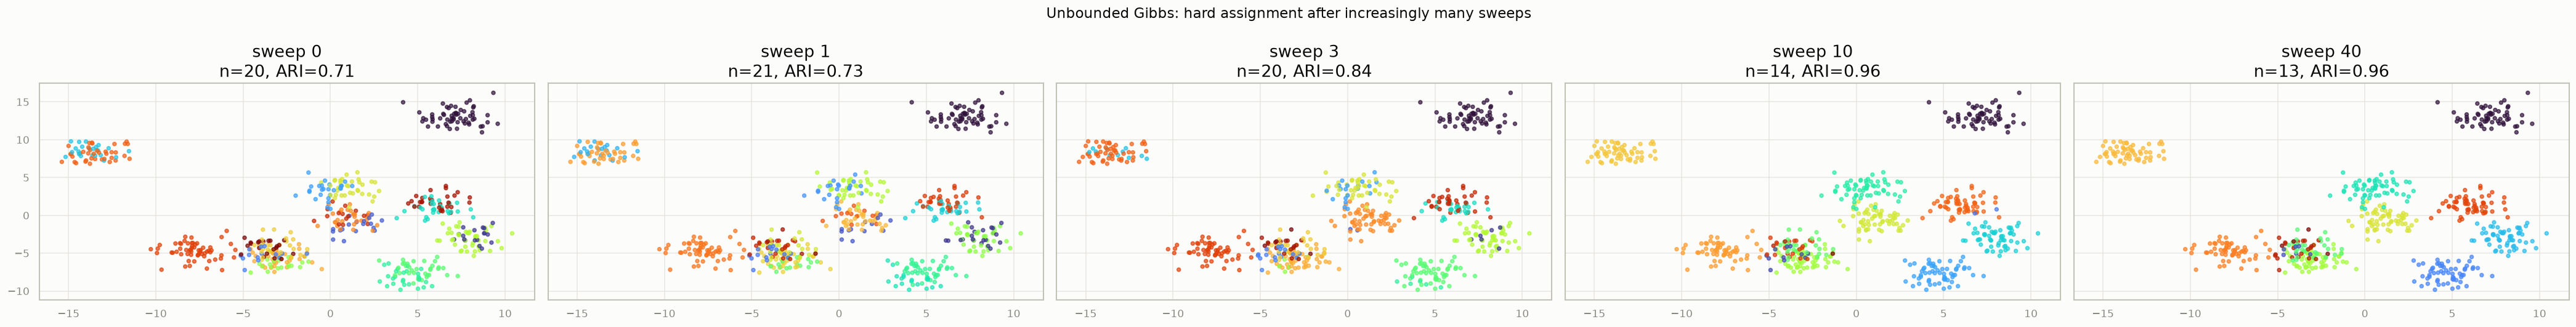

In [ ]:
SNAPSHOT_ITERS = [0, 1, 3, 10, N_SWEEPS]
_fig, _axes = plt.subplots(1, len(SNAPSHOT_ITERS), figsize=dynamic_figsize(1, len(SNAPSHOT_ITERS)), sharey=True)
for _ax, n_iter in zip(_axes, SNAPSHOT_ITERS):
    _model = GaussianMixture(n_components=None, max_components=None, max_iter=n_iter, burn_in=0, random_state=SEED, device='cpu', weight_threshold=1.0, mean_prior=MEAN_PRIOR, mean_precision_prior=MEAN_PRECISION_PRIOR, covariance_prior=COVARIANCE_PRIOR, degrees_of_freedom_prior=DEGREES_OF_FREEDOM_PRIOR)
    _model.fit(X)
    predicted = _model.predict(X)
    ari = adjusted_rand_score(true_labels.numpy(), predicted.numpy())
    _ax.scatter(X_pca[:, 0], X_pca[:, 1], c=predicted.numpy(), cmap='turbo', s=12, alpha=0.7)
    _ax.set_title(f'sweep {n_iter}\nn={_model.n_components_}, ARI={ari:.2f}')
_fig.suptitle('Unbounded Gibbs: hard assignment after increasingly many sweeps', fontsize=14)
plt.tight_layout()
plt.gcf()

Sweep 0 starts from many small kmeans-seeded fragments (colors are
essentially noise at this point). Within a handful of sweeps, the
well-separated pairs already merge down into single components; the
genuinely close pairs typically take longer to settle, if they fully
separate at all within the sweep budget shown here -- this is the
"merging is easy, splitting is slow" behavior described in the design
doc.

### 2.2 The component-count trajectory

Unlike EM's log-likelihood (which increases monotonically), Gibbs sampling's
`n_components_history_` is a *trace* -- it can rise and fall sweep to sweep
as tables are created and destroyed, and is only expected to *stabilize*
once the sampler has mixed, not converge to a fixed point. `burn_in=0` here
(unlike the default `max_iter // 5`) so we can see the early, volatile
sweeps too, which a real analysis would discard.

Final n_components_ (weight_threshold=1.0): 13


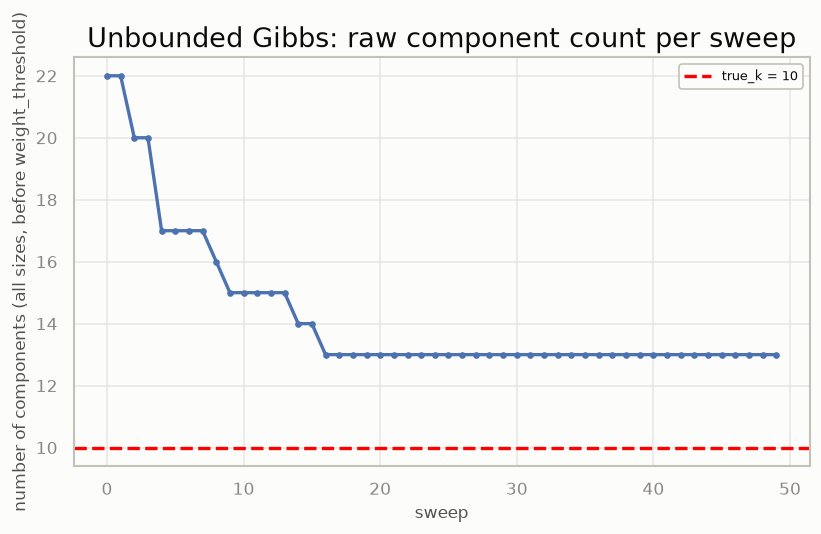

In [ ]:
_model = GaussianMixture(n_components=None, max_components=None, max_iter=N_SWEEPS + 10, burn_in=0, random_state=SEED, device='cpu', weight_threshold=1.0, mean_prior=MEAN_PRIOR, mean_precision_prior=MEAN_PRECISION_PRIOR, covariance_prior=COVARIANCE_PRIOR, degrees_of_freedom_prior=DEGREES_OF_FREEDOM_PRIOR)
_model.fit(X)
history = _model.n_components_history_
_fig, _ax = plt.subplots(figsize=dynamic_figsize(1, 1))
_ax.plot(range(len(history)), history, marker='o', markersize=3, color='#4C72B0')
_ax.axhline(true_k, color='red', linestyle='--', label=f'true_k = {true_k}')
_ax.set_xlabel('sweep')
_ax.set_ylabel('number of components (all sizes, before weight_threshold)')
_ax.set_title('Unbounded Gibbs: raw component count per sweep')
_ax.legend()
plt.tight_layout()
print(f'Final n_components_ (weight_threshold={_model.weight_threshold}): {_model.n_components_}')
_fig

### 2.3 Truncated and unbounded Gibbs agree, given the same starting point

Both variants resample assignments from the same occupancy-driven rule
(`n_k` for unbounded, `n_k + alpha/K` for truncated -- see section 1 above).
Given the *same* initial `K` for the kmeans seeding both use, they should
reach the identical partition for a given `random_state`.

`init_k` is what makes this a guarantee rather than a coincidence -- passing
the same value to unbounded's `init_k` as truncated's `max_components` pins
both to the identical k-means seed regardless of `n_samples`, instead of
relying on unbounded's automatic `_resolve_max_components` heuristic
happening to land on the same number.

In [ ]:
K_SEED = 20  # shared starting K, passed explicitly to both -- see the note above

model_trunc = GaussianMixture(n_components=None, max_components=K_SEED, max_iter=N_SWEEPS,
                              random_state=SEED, device='cpu', weight_threshold=1.0,
                              mean_prior=MEAN_PRIOR, mean_precision_prior=MEAN_PRECISION_PRIOR,
                              covariance_prior=COVARIANCE_PRIOR, degrees_of_freedom_prior=DEGREES_OF_FREEDOM_PRIOR)
model_trunc.fit(X)

model_unbounded = GaussianMixture(n_components=None, max_components=None, init_k=K_SEED, max_iter=N_SWEEPS, burn_in=10,
                                  random_state=SEED, device='cpu', weight_threshold=1.0,
                                  mean_prior=MEAN_PRIOR, mean_precision_prior=MEAN_PRECISION_PRIOR,
                                  covariance_prior=COVARIANCE_PRIOR, degrees_of_freedom_prior=DEGREES_OF_FREEDOM_PRIOR)
model_unbounded.fit(X)

pred_trunc = model_trunc.predict(X)
pred_unbounded = model_unbounded.predict(X)
agreement = adjusted_rand_score(pred_trunc.numpy(), pred_unbounded.numpy())

print(f"Truncated (K_max={K_SEED}):  n_components_={model_trunc.n_components_}")
print(f"Unbounded (seed K={K_SEED}): n_components_={model_unbounded.n_components_}")
print(f"ARI between the two partitions: {agreement:.3f}  (1.0 = identical)")

Truncated (K_max=20):  n_components_=12
Unbounded (seed K=20): n_components_=13
ARI between the two partitions: 0.973  (1.0 = identical)


## 3. Validating at scale: three rounds of comparison

Having seen *how* the sampler moves on one small example, this section
checks *how well it does* against a classical `GaussianMixture` and against
its own truncated/unbounded variants, systematically -- at three true
cluster counts (5, 10, 20), three times (no overlap, overlap, non-Gaussian
overlapping shapes).

### Synthetic 10-dimensional data

Three examples per round -- **5**, **10**, and **20** true clusters -- each
with **1,000 points total** (200 / 100 / 50 per cluster respectively; the
fast documentation build, `TGMM_DOCS_FAST=1`, uses 600 points and fewer Gibbs
sweeps), in $d=10$ dimensions. Cluster centers (and, in the non-Gaussian round, each
cluster's own shape parameters) are drawn from a single seeded random
stream, one cluster at a time -- so the first 5 clusters drawn are
*exactly* the 5 used in the `true_k=5` column, the first 10 are exactly
the 10 used in `true_k=10`, and so on. Combined with a **shared PCA
projection** (fit once on the full 20-cluster data and reused for every
column, rather than each column fitting its own) and a **shared color
palette** (cluster index `i` is always the same color, in every column
and every row), the same physical cluster looks the same wherever it
appears.

In [ ]:
N_TOTAL_1 = 600 if FAST else 1000
D_1 = 10
CLUSTER_COUNTS = [5, 10, 20]
K_MAX = max(CLUSTER_COUNTS)
N_COLORS = 40
# One consistent color per cluster index, shared across every column/row/round.
# Sized generously above K_MAX (not just to it): a fitted GMM/Gibbs-mode row can
# report more "active" components than the true cluster count when a
# truncated Gibbs run hasn't fully pruned its (larger) K_max slots down yet,
# and indexing past a too-small color list would raise IndexError.
_cmap = plt.get_cmap('turbo')
MASTER_COLORS = [_cmap(i / (N_COLORS - 1)) for i in range(N_COLORS)]

def make_high_dim_blobs(k, n_per_cluster, spread, d=D_1, seed=SEED):
    rng = np.random.RandomState(seed)
    centers = [rng.randn(d) * spread for _ in range(k)]
    covs = [np.eye(d) for _ in range(k)]
    X, labels = generate_gmm_data(centers, covs, [n_per_cluster] * k, random_state=seed)
    true_means = torch.tensor(np.stack(centers), dtype=torch.float64)
    true_covs = torch.eye(d, dtype=torch.float64).unsqueeze(0).repeat(k, 1, 1)
    return (X.double(), labels, true_means, true_covs, None)

### Visualizing high-dimensional Gaussians with `plot_gmm`

`plot_gmm` only accepts 2D data and a `gmm`-like object with 2D
`.means_`/`.covariances_`. Rather than *re-fitting* a separate 2D model
(which would show a different model's solution, not this one's), we use
the exact linear-projection result already established in this repo's
`08_pca_plotting.ipynb`: for a PCA projection $y = A(x - \bar{x})$, a Gaussian
component transforms as

$$\mathcal{N}(x; \mu_k, \Sigma_k) \;\longrightarrow\; \mathcal{N}(y; A(\mu_k - \bar{x}),\, A \Sigma_k A^T),$$

i.e. the 2D ellipse is the *exact* shadow of the original high-dimensional
Gaussian, not an approximation (even when the underlying cluster itself
isn't Gaussian -- see the non-Gaussian round below -- this is still the
exact projection of whatever mean/covariance we hand it, e.g. a
moment-matched approximation of the true shape). This lets us plot the
true generating clusters, a fitted Gibbs-mode `GaussianMixture`'s
components, or a fitted classical `GaussianMixture`'s components, through
the same PCA projection
as the data -- via a lightweight proxy object exposing what `plot_gmm`
needs (`.means_`, `.covariances_`, `.weights_`, `.covariance_type`,
`.n_components`, `.predict()`), without ever re-fitting anything in 2D.

In [ ]:
# Exact 2D projection of Gaussian means/covariances through a fitted sklearn PCA.
def project_gaussian_params(means, covariances, pca):
    A = torch.tensor(pca.components_, dtype=torch.float64)
    mean_shift = torch.tensor(pca.mean_, dtype=torch.float64)
    means_2d = (means - mean_shift) @ A.T
    covariances_2d = torch.matmul(torch.matmul(A.unsqueeze(0), covariances), A.T.unsqueeze(0))
    return means_2d, covariances_2d

# Minimal object satisfying plot_gmm's `gmm=` interface for pre-projected 2D params.
def make_viz_proxy(means_2d, covariances_2d, weights, predicted_labels):
    return SimpleNamespace(
        n_components=means_2d.shape[0],
        means_=means_2d,
        covariances_=covariances_2d,
        weights_=weights,
        covariance_type='full',
        predict=lambda X: predicted_labels,
    )

# Assigns each point to its best *active* Gibbs-mode component only (relative
# index, 0..n_active-1, matching model.means_[model.active_]'s ordering) --
# a near-empty pruned component shouldn't receive hard-assigned points when
# reporting/plotting the model's solution. NOTE: this is what the ARI
# table below scores for Gibbs-mode rows, and it can differ from plain
# model.predict(X), which does argmax over *all* K slots (including
# inactive ones) and is what a reader would get calling the public API
# directly. Classical GaussianMixture has no pruning concept, so its rows
# use gmm.predict(X) directly.
def restricted_predict(model, X):
    proba = model.predict_proba(X)
    return proba[:, model.active_].argmax(dim=1)

### Comparison driver

`run_round` generates the three (nested) datasets for a given `spread`,
fits **one shared PCA** on the full `true_k=20` data and reuses it to
project every column, then for each true cluster count builds a single
4-row column, all via the same `plot_gmm` tool and the shared PCA + color
palette:

1. **True clusters and samples** -- the generating Gaussians (or, for the
   non-Gaussian round, a moment-matched Gaussian approximation of the
   true shape).
2. **Classical `GaussianMixture`, K chosen by minimum BIC over `K=1..30`**
   -- i.e. "if all you have is a classical GMM and this data, how well can
   *it* find the right number of clusters, without borrowing Gibbs's
   answer?" Each `K` is fit with `n_init=5` random restarts and the best
   kept (`GaussianMixture` already does this internally, tracked via
   `best_random_state_`). Raw log-likelihood can't be used for this: it's
   monotonic in `K` on training data (every extra component can only fit
   at least as well, never worse), so a "minimum-LL" sweep just picks
   `K=30`, the ceiling of whatever range you search, and would keep
   climbing past it. AIC (`gmm.aic(X)`) has the same problem in practice
   here -- its complexity penalty (`2 * n_params`) is weak enough, for
   `d=10` `full`-covariance components (66 params each), that it too keeps
   improving all the way to `K=30` without turning back up, so it isn't a
   reliable stopping rule on this data either; the plots below show both
   curves so this is visible directly rather than asserted. BIC's
   penalty (`n_params * ln(n_samples)`) is steep enough to actually turn
   around -- but that steepness can also make it *undershoot* the true
   count, particularly with real cluster overlap (see Round 2).
3. **Gibbs (truncated)** -- `GaussianMixture(n_components=None, max_components=30)`.
4. **Gibbs (unbounded)** -- `GaussianMixture(n_components=None, max_components=None, init_k=30)`.
   `init_k` pins unbounded's initial k-means seed to the *same* `K=30`
   truncated starts from (rather than truncated and unbounded silently
   getting different starting points from two different mechanisms,
   `max_components` vs. the automatic `_resolve_max_components`
   heuristic) -- see [the DPGMM design doc](https://github.com/adriansousapoza/tgmm/blob/main/docs/superpowers/specs/2026-07-28-dpgmm-design.md). This removes one real source of
   truncated/unbounded disagreement, but not the only one: even from an
   identical starting partition, the two samplers resample from slightly
   different per-point rules (truncated: `n_k + alpha/K` over 30 fixed
   slots; unbounded: `n_k` over occupied tables plus a separate
   `alpha`-weighted new-table term), which converge to each other as `K`
   grows relative to the true count but aren't identical rule-for-rule --
   so a same-start pair can still, occasionally, settle into different
   local structure after a finite number of sweeps. Watch for this in the
   tables below rather than assuming a shared start guarantees a shared
   answer.

Every fitted row's title reports `n` (components), `K_max`/`init_k` where
relevant, `ARI` against the true labels, and `LL` (average
log-likelihood per point, `.score(X)`) -- so rows 2-4 are directly
comparable on the same scale. `weight_threshold=10` means a Gibbs-mode
component must own at least 1% of the 1,000 points to count toward
`n_components_` -- otherwise near-empty slots left over from a generous
truncation level would inflate the count (see [the DPGMM design doc](https://github.com/adriansousapoza/tgmm/blob/main/docs/superpowers/specs/2026-07-28-dpgmm-design.md)). The
table's ARI for Gibbs-mode rows is scored via `restricted_predict`
(hard-assignment restricted to *active* components only), which can
differ from calling `model.predict(X)` directly, since that does argmax
over every slot including inactive ones.

In [ ]:
WEIGHT_THRESHOLD = 0.01 * N_TOTAL_1
K_SWEEP_MAX = 22 if FAST else 30  # classical GMM's BIC/AIC sweep range, K=1..K_SWEEP_MAX
# Shared starting K for BOTH Gibbs variants (truncated's own cap, and unbounded's init_k override),
# so neither gets a head start or a disadvantage from a different k-means seed.
GIBBS_INIT_K = 30

def method_configs():
    return [
        ('gibbs_trunc', 'Gibbs (truncated)', dict(truncation_level=GIBBS_INIT_K, init_k=None)),
        ('gibbs_unbounded', 'Gibbs (unbounded)', dict(truncation_level=None, init_k=GIBBS_INIT_K)),
    ]

def fit_dpgmm_and_summarize(X, labels, pca, label, truncation_level, weight_threshold, random_state, init_k=None):
    extra = dict(max_iter=N_SWEEPS) if truncation_level is not None else dict(max_iter=N_SWEEPS, burn_in=(N_SWEEPS * 3) // 10)
    # Gibbs mode (n_components=None) requires an explicit NIW prior: suggest_priors gives a principled
    # starting point from a quick k-means partition into GIBBS_INIT_K groups (the same K both variants start from).
    mean_prior, mean_precision_prior, covariance_prior, degrees_of_freedom_prior = GaussianMixture.suggest_priors(X, n_components=GIBBS_INIT_K, random_state=SEED)
    # device='cpu' explicitly: GaussianMixture defaults to CUDA when available, and this notebook's
    # numpy()/adjusted_rand_score calls assume CPU tensors (1,000 x 10 data gains nothing from a GPU anyway).
    model = GaussianMixture(n_components=None, covariance_type='full', alpha=1.0, random_state=random_state, weight_threshold=weight_threshold, device='cpu', max_components=truncation_level, init_k=init_k, mean_prior=mean_prior, mean_precision_prior=mean_precision_prior, covariance_prior=covariance_prior, degrees_of_freedom_prior=degrees_of_freedom_prior, **extra)
    t0 = time.time()
    model.fit(X)
    elapsed = time.time() - t0
    predicted = restricted_predict(model, X)
    ari = adjusted_rand_score(labels.numpy(), predicted.numpy())
    ll = model.score(X)
    if truncation_level is not None:
        seed_str = f', K_max={truncation_level}'
    elif init_k is not None:
        seed_str = f', init_k={init_k}'
    else:
        seed_str = ''
    title = f'{label}\nn={model.n_components_}{seed_str}, ARI={ari:.2f}\nLL={ll:.2f}'
    active = model.active_
    means_2d, covs_2d = project_gaussian_params(model.means_[active], model.covariances_[active], pca)
    proxy = make_viz_proxy(means_2d, covs_2d, model.weights_[active], predicted)
    return dict(proxy=proxy, title=title, label=label, n_components_=model.n_components_, ari=ari, ll=ll, elapsed=elapsed)

def fit_gmm_and_summarize(X, labels, pca, n_components, random_state, max_attempts=4):
    t0 = time.time()
    last_error = None
    # A k-means-based empirical covariance init can occasionally isolate a single far-tail point into its own
    # cluster; torch.cov on 1 point is NaN, and GaussianMixture.fit() aborts the *entire* n_init batch the first
    # time any one restart hits that. Retrying the whole batch with a fresh base seed sidesteps it without
    # touching GaussianMixture itself. The n_init random-state bookkeeping warnings are expected noise from
    # this retry loop and are suppressed. Higher K in the BIC/AIC sweep hits this more often.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        for attempt in range(max_attempts):
            seed = random_state + attempt * 1000
            gmm = GaussianMixture(n_components=n_components, covariance_type='full', n_init=N_INIT, random_state=seed, device='cpu')
            try:
                gmm.fit(X)
                last_error = None
                break
            except ValueError as e:
                last_error = e
    if last_error is not None:
        raise RuntimeError(f'GaussianMixture(K={n_components}) failed to fit after {max_attempts} attempts (degenerate covariance from a near-empty cluster each time): {last_error}')
    elapsed = time.time() - t0
    predicted = gmm.predict(X)
    ari = adjusted_rand_score(labels.numpy(), predicted.numpy())
    ll = gmm.score(X)
    label = f'GMM (K={n_components})'
    title = f'{label}\nARI={ari:.2f}\nLL={ll:.2f}'
    means_2d, covs_2d = project_gaussian_params(gmm.means_, gmm.covariances_, pca)
    proxy = make_viz_proxy(means_2d, covs_2d, gmm.weights_, predicted)
    return dict(proxy=proxy, title=title, label=label, n_components_=n_components, ari=ari, ll=ll, elapsed=elapsed, bic=gmm.bic(X), aic=gmm.aic(X), gmm=gmm)

def fit_gmm_via_bic_sweep(X, labels, pca, k_range, random_state):
    """Fit every K in k_range once and keep the minimum-BIC fit as the row shown in the main grid;
    the whole sweep is returned too (as 'sweep') for the BIC/AIC-vs-K curve, and 'elapsed' is its total cost."""
    t0 = time.time()
    trials = [fit_gmm_and_summarize(X, labels, pca, k, random_state) for k in k_range]
    elapsed = time.time() - t0
    best = dict(min(trials, key=lambda r: r['bic']))
    best['label'] = f"GMM (min BIC, K={best['n_components_']})"
    best['title'] = f"{best['label']}\nARI={best['ari']:.2f}\nLL={best['ll']:.2f}"
    best['elapsed'] = elapsed
    best['sweep'] = trials
    return best

def run_round(round_name, spread, data_fn=make_high_dim_blobs, legend_info_fn=None):
    """Run one comparison round. Prints the per-round table and returns a dict with the
    results and the two figures (BIC/AIC curves, and the 4 x 3 comparison grid)."""
    # --- generate the three (nested) datasets ---
    datasets = {}
    same_cluster_baseline = math.sqrt(2 * D_1)
    print(f'{round_name}: same-cluster baseline distance sqrt(2d) = {same_cluster_baseline:.2f}')
    for k in CLUSTER_COUNTS:
        n_per = N_TOTAL_1 // k
        X, labels, true_means, true_covs, cluster_info = data_fn(k, n_per, spread)
        datasets[k] = dict(X=X, labels=labels, true_means=true_means, true_covs=true_covs, cluster_info=cluster_info)
        center_dists = torch.pdist(true_means)
        print(f'  true_k={k:>2}: true-center pairwise distance min={center_dists.min():.2f}, mean={center_dists.mean():.2f}')
    # --- shared PCA: fit once on the largest (nested-superset) dataset ---
    shared_pca = PCA(n_components=2, random_state=SEED).fit(datasets[K_MAX]['X'].numpy())
    for k in CLUSTER_COUNTS:
        datasets[k]['pca'] = shared_pca
        datasets[k]['X_pca'] = shared_pca.transform(datasets[k]['X'].numpy())
    # --- fit the GMM row (BIC sweep) and both Gibbs rows first: the BIC/AIC curve figure and the main grid both need them ---
    results = {}
    gmm_rows = {}
    for k in CLUSTER_COUNTS:
        d = datasets[k]
        gmm_rows[k] = fit_gmm_via_bic_sweep(d['X'], d['labels'], d['pca'], range(1, K_SWEEP_MAX + 1), SEED)
        results[k, 'gmm_best'] = gmm_rows[k]
    # --- BIC/AIC-vs-K curves (left axis) with the raw log-likelihood on a twin right axis (very different scale).
    # LL is monotonic in K on training data (every extra component can only fit at least as well), so it has no
    # interior optimum and just keeps climbing: it is plotted for comparison, not as a selector. Data curves are
    # solid; the vertical "best K" markers are dashed in their curve's own colour; true_k is a neutral gray dotted line. ---
    fig_ic, axes_ic = plt.subplots(1, len(CLUSTER_COUNTS), figsize=dynamic_figsize(1, len(CLUSTER_COUNTS)), sharey=False)
    for col, k in enumerate(CLUSTER_COUNTS):
        sweep = gmm_rows[k]['sweep']
        ks = [t['n_components_'] for t in sweep]
        bic_best_k = gmm_rows[k]['n_components_']
        aic_best_k = min(sweep, key=lambda t: t['aic'])['n_components_']
        ll_best_k = max(sweep, key=lambda t: t['ll'])['n_components_']
        ax = axes_ic[col]
        ax.plot(ks, [t['bic'] for t in sweep], marker='o', markersize=3, color='#4C72B0', linestyle='-', label='BIC')
        ax.plot(ks, [t['aic'] for t in sweep], marker='o', markersize=3, color='#DD8452', linestyle='-', label='AIC')
        ax.axvline(k, color='gray', linestyle=':', label=f'true_k={k}')
        ax.axvline(bic_best_k, color='#4C72B0', linestyle='--', alpha=0.6, label=f'BIC-best K={bic_best_k}')
        ax.axvline(aic_best_k, color='#DD8452', linestyle='--', alpha=0.6, label=f'AIC-best K={aic_best_k}')
        ax.set_xlabel('K')
        if col == 0:
            ax.set_ylabel('information criterion (lower is better)')
        ax_ll = ax.twinx()
        ax_ll.plot(ks, [t['ll'] for t in sweep], marker='o', markersize=3, color='#55A868', linestyle='-', alpha=0.8, label='log-likelihood (training, monotonic)')
        ax.axvline(ll_best_k, color='#55A868', linestyle='--', alpha=0.6, label=f'best-LL K={ll_best_k}')  # highest LL is "best" -- always K_SWEEP_MAX
        if col == len(CLUSTER_COUNTS) - 1:
            ax_ll.set_ylabel('avg. log-likelihood per point')
        ax.set_title(f'true_k={k}')
        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax_ll.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labels1 + labels2, fontsize='x-small', loc='center right')
    fig_ic.suptitle(f'{round_name}: classical GMM, BIC/AIC (left) vs log-likelihood (right, monotonic) over K=1..{K_SWEEP_MAX}', fontsize=13)
    fig_ic.tight_layout()
    # --- one combined 4-row x 3-col figure: true data / GMM / Gibbs truncated / Gibbs unbounded
    # (rows 2-3 start from the same K, GIBBS_INIT_K) ---
    fig, axes = plt.subplots(4, 3, figsize=dynamic_figsize(4, 3))
    for col, k in enumerate(CLUSTER_COUNTS):
        d = datasets[k]
        X_pca = d['X_pca']
        pca = d['pca']
        # Row 0: true clusters, samples, and generating distributions
        means_2d, covs_2d = project_gaussian_params(d['true_means'], d['true_covs'], pca)
        proxy = make_viz_proxy(means_2d, covs_2d, torch.full((k,), 1.0 / k), d['labels'])
        plot_gmm(X_pca, gmm=proxy, color_by_cluster=True, cluster_colors=MASTER_COLORS, show_ellipses=True, ellipse_std_devs=[2], point_size=8, legend=False, ax=axes[0, col], title=f'true_k={k}: {k} true clusters, n={len(X_pca)}')
        dpgmm_rows = {}
        for key, label, cfg in method_configs():
            r = fit_dpgmm_and_summarize(d['X'], d['labels'], pca, label, cfg['truncation_level'], WEIGHT_THRESHOLD, SEED, init_k=cfg['init_k'])
            dpgmm_rows[key] = r
            results[k, key] = r
        gmm_r = gmm_rows[k]
        for row_idx, r in enumerate([gmm_r, dpgmm_rows['gibbs_trunc'], dpgmm_rows['gibbs_unbounded']], start=1):
            plot_gmm(X_pca, gmm=r['proxy'], color_by_cluster=True, cluster_colors=MASTER_COLORS, show_ellipses=True, ellipse_std_devs=[2], point_size=8, legend=False, ax=axes[row_idx, col], title=f"true_k={k}: {r['title']}")
    fig.suptitle(f'{round_name}: true data vs. classical GMM vs. Gibbs-mode GaussianMixture (PCA projection)', fontsize=16)
    # one legend for the whole figure (only when distribution info was supplied -- rounds 1/2 are pure Gaussian)
    if legend_info_fn is not None:
        handles = legend_info_fn(datasets[K_MAX]['cluster_info'])
        fig.legend(handles=handles, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='x-small')
    fig.tight_layout()
    # --- summary table ---
    lines = [f"{'true_k':>6}  {'method':<24} {'n':>3}  {'ARI':>6}  {'LL':>9}  {'seconds':>8}"]
    for k in CLUSTER_COUNTS:
        r = results[k, 'gmm_best']
        lines.append(f"{k:>6}  {r['label']:<24} {r['n_components_']:>3}  {r['ari']:>6.3f}  {r['ll']:>9.3f}  {r['elapsed']:>8.2f}*")
        for key, label, _ in method_configs():
            r = results[k, key]
            lines.append(f"{k:>6}  {label:<24} {r['n_components_']:>3}  {r['ari']:>6.3f}  {r['ll']:>9.3f}  {r['elapsed']:>8.2f}")
    lines.append(f"\n* GMM row's seconds is the *whole* K=1..{K_SWEEP_MAX} sweep, not just the winning fit.")
    print('\n'.join(lines))
    return dict(results=results, fig_ic=fig_ic, fig_grid=fig)

### Round 1: well-separated clusters (no overlap)

Cluster centers drawn with `spread=8.0` -- in $d=10$ with identity
covariance, two points from the *same* cluster are typically about
$\sqrt{2d} \approx 4.5$ apart, so centers this far apart are unambiguous.

In [ ]:
round_no_overlap = run_round('No overlap', spread=8.0)

No overlap: same-cluster baseline distance sqrt(2d) = 4.47
  true_k= 5: true-center pairwise distance min=27.48, mean=42.17
  true_k=10: true-center pairwise distance min=16.57, mean=35.08
  true_k=20: true-center pairwise distance min=16.16, mean=36.05
true_k  method                     n     ARI         LL   seconds
     5  GMM (min BIC, K=5)         5   1.000    -15.393      0.50*
     5  Gibbs (truncated)          5   1.000    -15.447      6.00
     5  Gibbs (unbounded)          5   1.000    -15.447      8.09
    10  GMM (min BIC, K=11)       11   0.972    -15.712      0.35*
    10  Gibbs (truncated)         11   0.973    -15.745      5.95
    10  Gibbs (unbounded)         10   1.000    -15.928      8.32
    20  GMM (min BIC, K=15)       15   0.782    -16.969      0.26*
    20  Gibbs (truncated)         23   0.963    -15.846      5.94
    20  Gibbs (unbounded)         23   0.962    -15.786      9.42

* GMM row's seconds is the *whole* K=1..22 sweep, not just the winning fit.


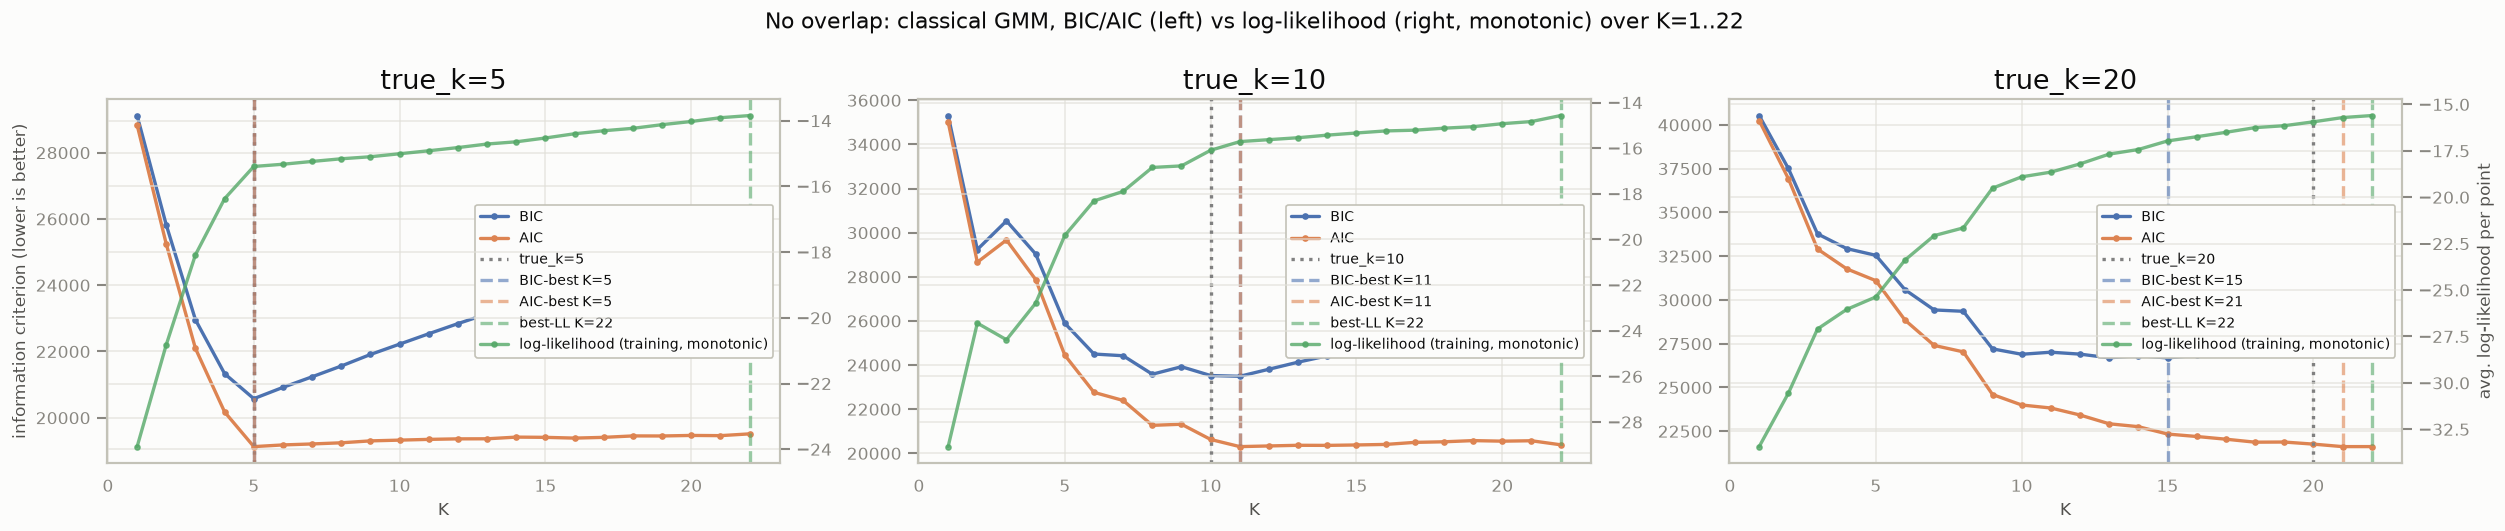

In [ ]:
round_no_overlap['fig_ic']

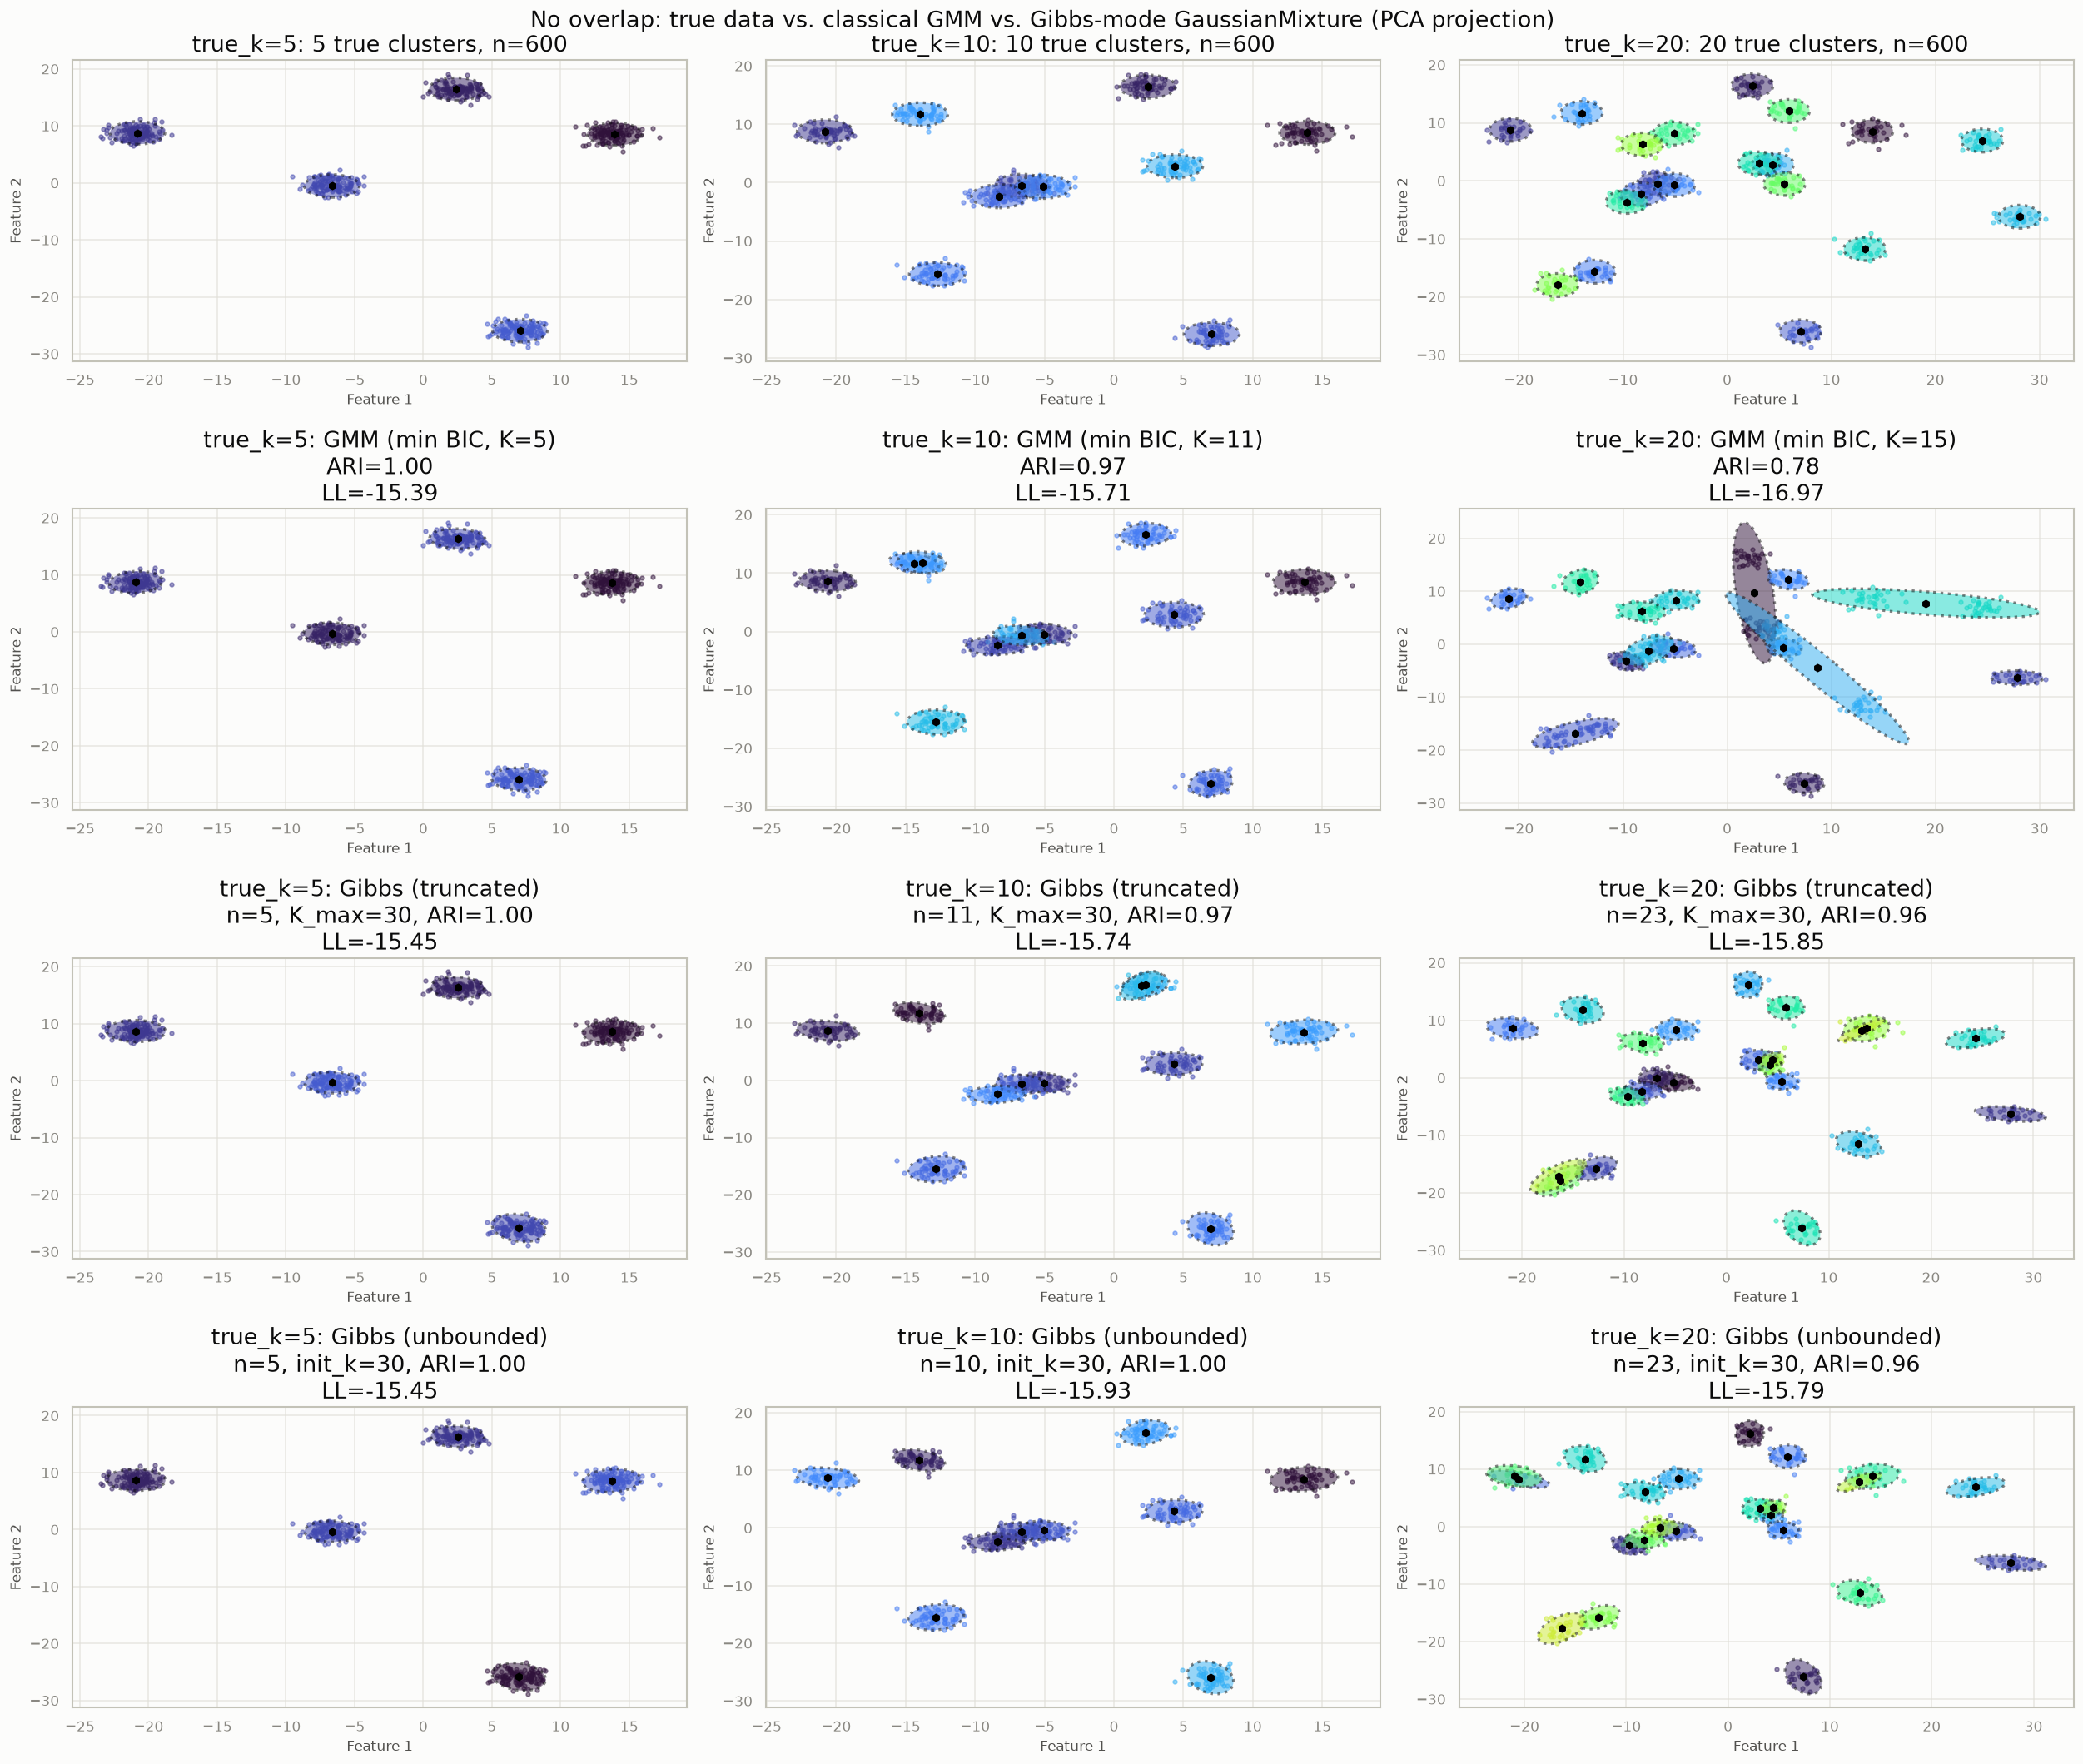

In [ ]:
round_no_overlap['fig_grid']

### Round 2: overlapping clusters

Same three examples, same total sample sizes -- only `spread` changes, to
`4.0`, so cluster centers sit closer together than the $\sqrt{2d}\approx 4.5$
same-cluster baseline. Some points now sit genuinely ambiguously between
two generating Gaussians.

Note: with real overlap, the Gibbs chains' `n_components_` can vary by
`random_state` -- e.g. at `true_k=10` truncated Gibbs lands on a clean 10
for most seeds but occasionally reports 11 (a small, genuinely ambiguous
cluster splits in two for that particular chain). This is ordinary
sampler-to-sampler variability on ambiguous data, not a bug -- in the no-overlap round, by contrast, the Gibbs chains land at or close to the true count in every example (with a smaller sample or fewer sweeps, as in the fast documentation build, they may still be carrying a few small extra components that a longer run prunes).

Truncated and unbounded Gibbs both start from the *same* `K=30` k-means
partition here (`GIBBS_INIT_K`, via truncated's own `max_components`
and unbounded's `init_k`).

That does not mean the two chains
always agree, though: they still resample from slightly different rules
each sweep (`n_k + alpha/K` over fixed slots vs. `n_k` over occupied
tables plus a separate new-table term), which converge to each other as
`K` grows relative to the true count but aren't identical move-for-move
-- so occasional small disagreements between the truncated and unbounded
rows below, even from the same starting partition, are that, not a bug.

In [ ]:
round_overlap = run_round('Overlap', spread=4.0)

Overlap: same-cluster baseline distance sqrt(2d) = 4.47
  true_k= 5: true-center pairwise distance min=13.74, mean=21.08
  true_k=10: true-center pairwise distance min=8.29, mean=17.54
  true_k=20: true-center pairwise distance min=8.08, mean=18.02
true_k  method                     n     ARI         LL   seconds
     5  GMM (min BIC, K=5)         5   1.000    -15.393      0.47*
     5  Gibbs (truncated)          5   1.000    -15.412      5.99
     5  Gibbs (unbounded)          5   1.000    -15.412      8.18
    10  GMM (min BIC, K=8)         8   0.734    -16.443      0.37*
    10  Gibbs (truncated)         10   1.000    -15.761      5.92
    10  Gibbs (unbounded)         10   1.000    -15.721      8.51
    20  GMM (min BIC, K=9)         9   0.530    -18.159      0.24*
    20  Gibbs (truncated)         23   0.969    -15.478      5.91
    20  Gibbs (unbounded)         27   0.924    -15.127      9.52

* GMM row's seconds is the *whole* K=1..22 sweep, not just the winning fit.


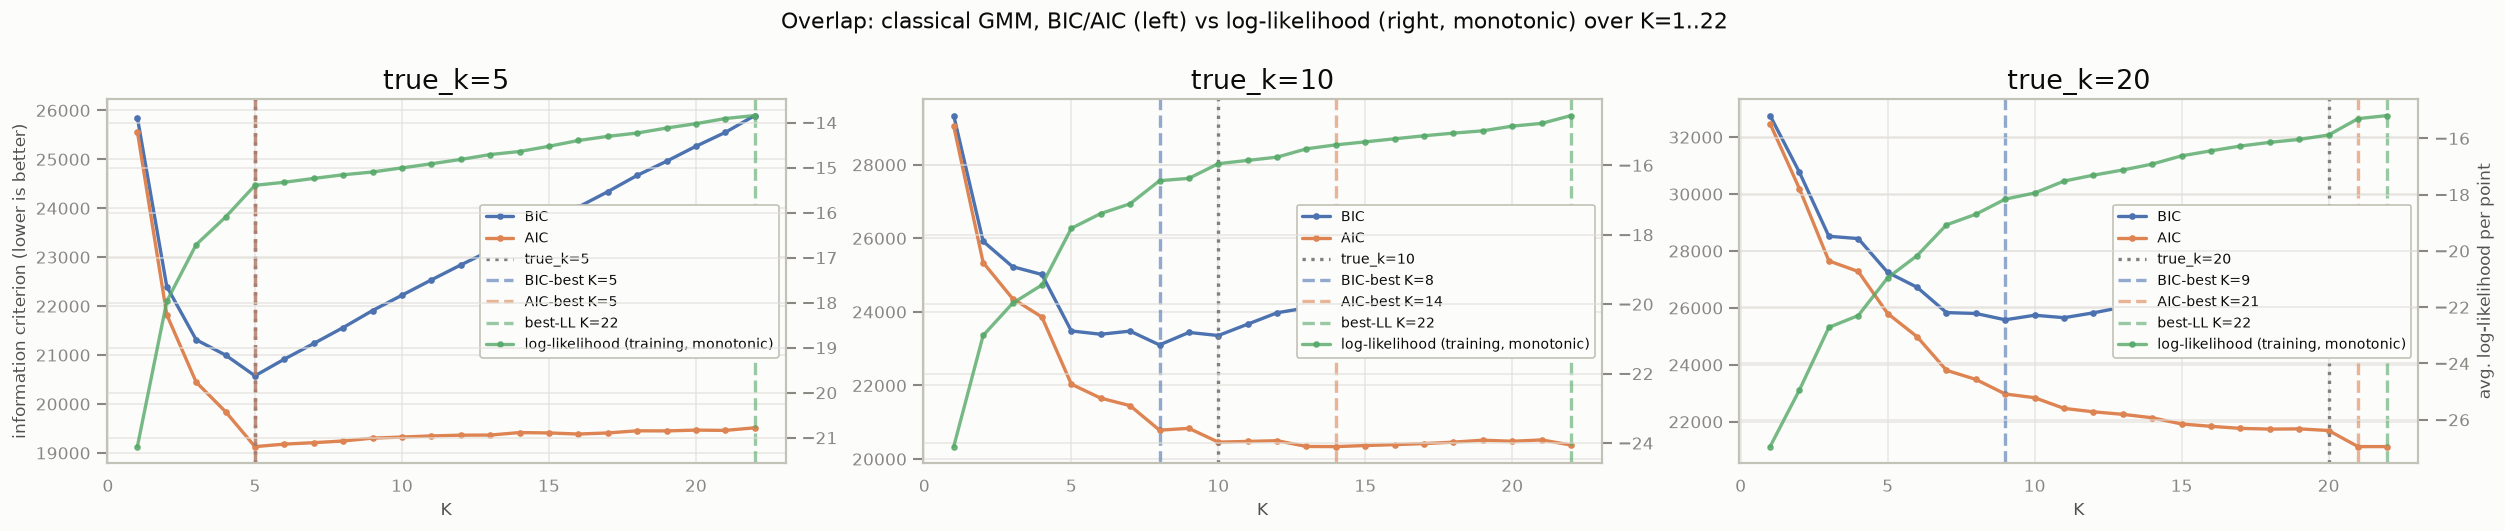

In [ ]:
round_overlap['fig_ic']

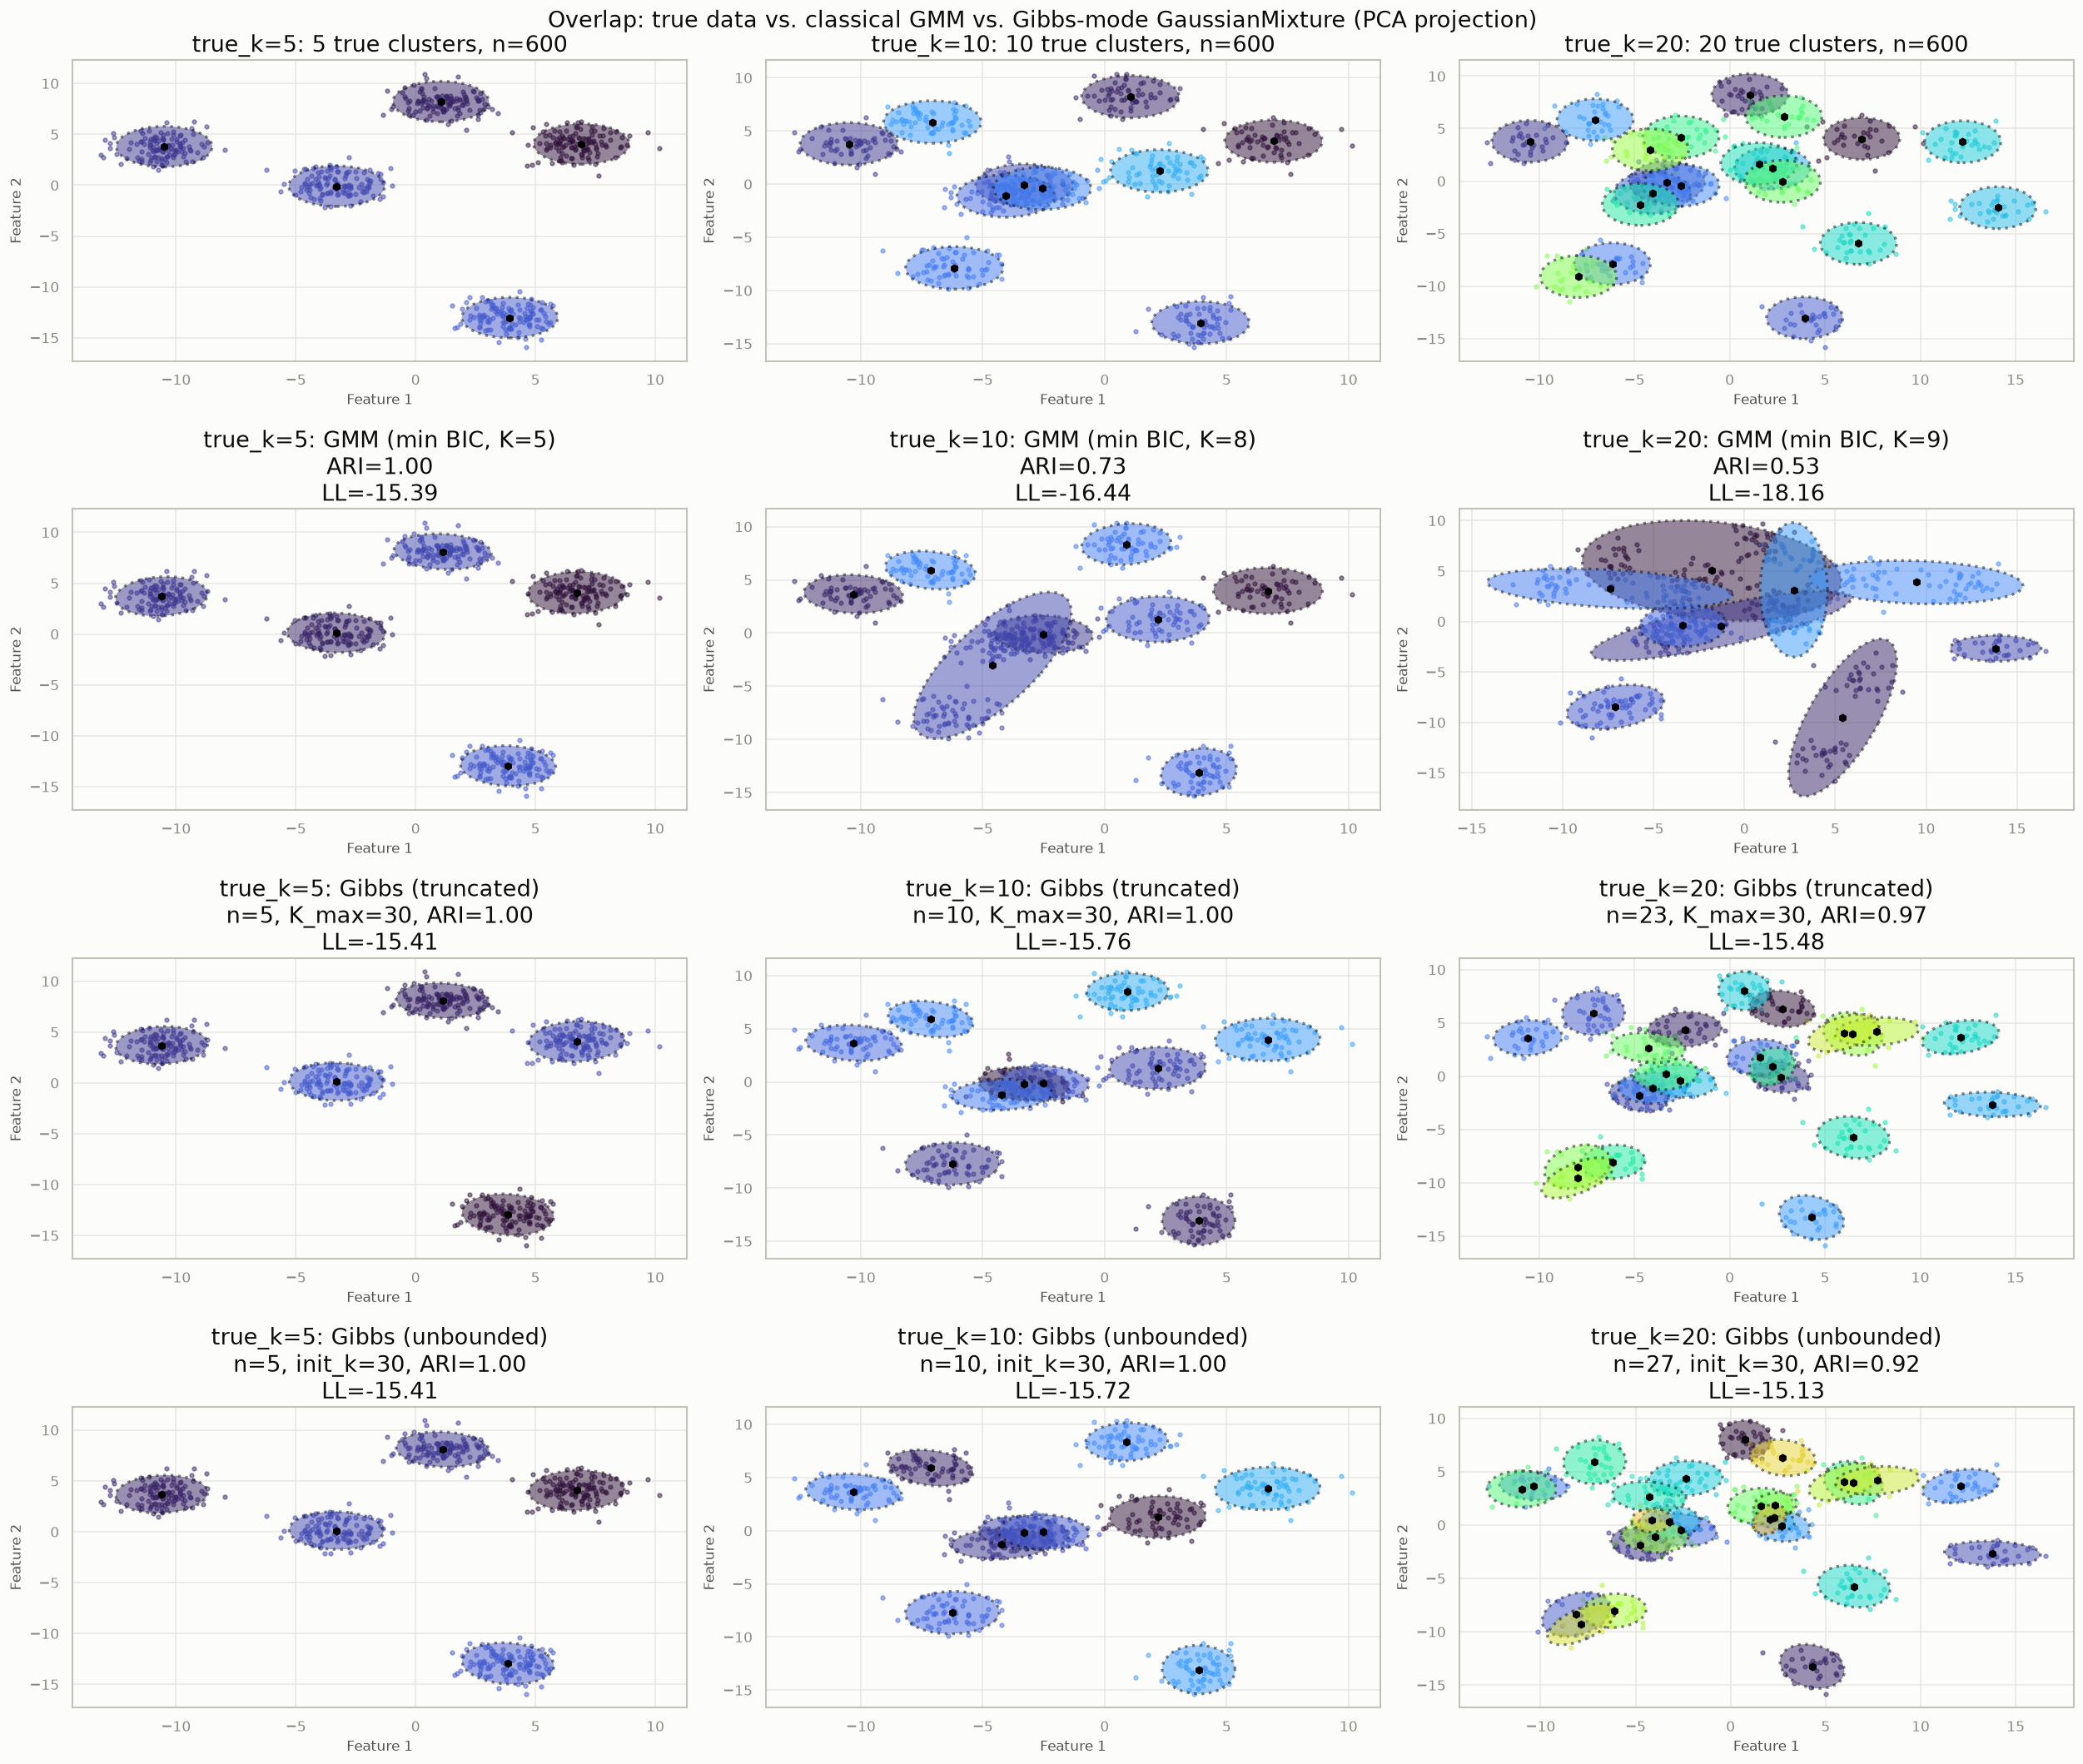

In [ ]:
round_overlap['fig_grid']

### Round 3: non-Gaussian, overlapping cluster shapes

Both Gibbs-mode fitting and classical EM fitting (both via
`GaussianMixture`) assume every cluster is Gaussian. This round breaks that assumption *and* keeps the clusters
overlapping (`spread=4.0`, as in round 2), so shape mismatch and overlap
now compound rather than being tested in isolation. Clusters alternate
between two non-Gaussian shapes, **each with its own randomly-drawn
parameters** rather than a single shared radius/shape/scale for every
cluster of that family:

- **Uniform ball** (even-indexed clusters): points drawn uniformly from a
  $d$-dimensional ball -- flat density inside a hard boundary, nothing
  like a Gaussian's soft tails. Each ball cluster gets its own radius,
  drawn so its per-coordinate variance is Uniform(0.5, 2.0).
- **Gamma-skewed / long-tailed** (odd-indexed clusters): each coordinate
  drawn from a shifted Gamma distribution -- long tail on the positive
  side, short/bounded on the negative side, unlike a Gaussian's symmetric
  tails. Each Gamma cluster gets its own shape parameter (Uniform(1.0,
  4.0) -- smaller shape means a more exaggerated, longer tail) and a
  scale chosen so its per-coordinate variance is also Uniform(0.5, 2.0).

The "true" ellipses plotted below are therefore a *moment-matched*
Gaussian approximation of each true cluster's actual (non-Gaussian)
shape at its own variance, not an exact depiction of it -- there is no
Gaussian that exactly draws a flat disk or a one-sided tail. The legend
states, per cluster, which distribution generated it and its own
parameters.

Non-Gaussian shapes also make the Gibbs samplers' own NIW-conjugate math
a worse fit to the data than in rounds 1-2 (it's still assuming Gaussian
components internally, same as classical GMM) -- so this round is where
truncated and unbounded Gibbs, even started from the same `K=30`
partition (see round 2's note), can diverge from each other more than in the
earlier rounds.

In [ ]:
def make_non_gaussian_blobs(k, n_per_cluster, spread, d=D_1, seed=SEED):
    # Two separate RNG streams, deliberately: per-cluster parameters (center, distribution kind,
    # radius/shape/scale) must consume a *fixed* number of draws per cluster, so that cluster i's
    # parameters come out identical regardless of k (nesting). Interleaving the per-point sampling
    # (a variable, n_per_cluster-sized batch) into the same stream would shift every later cluster's
    # parameters whenever n_per_cluster changes between columns, silently breaking nesting.
    param_rng = np.random.RandomState(seed)
    centers, cluster_info = ([], [])
    for i in range(k):
        center = param_rng.randn(d) * spread
        variance_target = param_rng.uniform(0.5, 2.0)
        if i % 2 == 0:
            R = math.sqrt(variance_target * (d + 2))
            cluster_info.append(dict(kind='ball', R=R, variance=variance_target))
        else:
            shape_param = param_rng.uniform(1.0, 4.0)
            scale_param = math.sqrt(variance_target / shape_param)
            cluster_info.append(dict(kind='gamma', shape=shape_param, scale=scale_param, variance=variance_target))
        centers.append(center)
    sample_rng = np.random.RandomState(seed + 12345)
    samples, labels, true_means, true_covs = ([], [], [], [])
    for i, (center, info) in enumerate(zip(centers, cluster_info)):
        if info['kind'] == 'ball':
            directions = sample_rng.randn(n_per_cluster, d)
            directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)
            radii = info['R'] * sample_rng.uniform(0.0, 1.0, size=n_per_cluster) ** (1.0 / d)
            pts = center + directions * radii[:, None]
        else:
            pts = center + (sample_rng.gamma(info['shape'], info['scale'], size=(n_per_cluster, d)) - info['shape'] * info['scale'])
        samples.append(pts)
        labels.extend([i] * n_per_cluster)
        true_means.append(center)
        true_covs.append(np.eye(d) * info['variance'])
    X = torch.tensor(np.concatenate(samples, axis=0), dtype=torch.float64)
    labels = torch.tensor(labels, dtype=torch.long)
    true_means = torch.tensor(np.stack(true_means), dtype=torch.float64)
    true_covs = torch.tensor(np.stack(true_covs), dtype=torch.float64)
    return (X, labels, true_means, true_covs, cluster_info)

def non_gaussian_legend_info(cluster_info):
    from matplotlib.lines import Line2D
    handles = []
    for i, info in enumerate(cluster_info):
        if info['kind'] == 'ball':
            text = f"{i + 1}: ball (R={info['R']:.2f})"
        else:
            text = f"{i + 1}: Γ-skew (shape={info['shape']:.1f}, scale={info['scale']:.2f})"
        handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=MASTER_COLORS[i], markersize=6, label=text))
    return handles
round_non_gaussian = run_round('Non-Gaussian (overlap)', spread=4.0, data_fn=make_non_gaussian_blobs, legend_info_fn=non_gaussian_legend_info)

Non-Gaussian (overlap): same-cluster baseline distance sqrt(2d) = 4.47
  true_k= 5: true-center pairwise distance min=15.08, mean=19.06
  true_k=10: true-center pairwise distance min=10.54, mean=17.45
  true_k=20: true-center pairwise distance min=8.39, mean=17.15
true_k  method                     n     ARI         LL   seconds
     5  GMM (min BIC, K=5)         5   1.000    -17.918      0.46*
     5  Gibbs (truncated)          6   0.982    -17.670      5.92
     5  Gibbs (unbounded)          6   0.979    -17.760      8.37
    10  GMM (min BIC, K=7)         7   0.734    -18.375      0.31*
    10  Gibbs (truncated)         14   0.941    -16.853      5.89
    10  Gibbs (unbounded)         12   0.965    -16.923      8.99
    20  GMM (min BIC, K=9)         9   0.495    -20.137      0.24*
    20  Gibbs (truncated)         25   0.920    -17.077      5.90
    20  Gibbs (unbounded)         25   0.923    -16.456     10.01

* GMM row's seconds is the *whole* K=1..22 sweep, not just the winning 

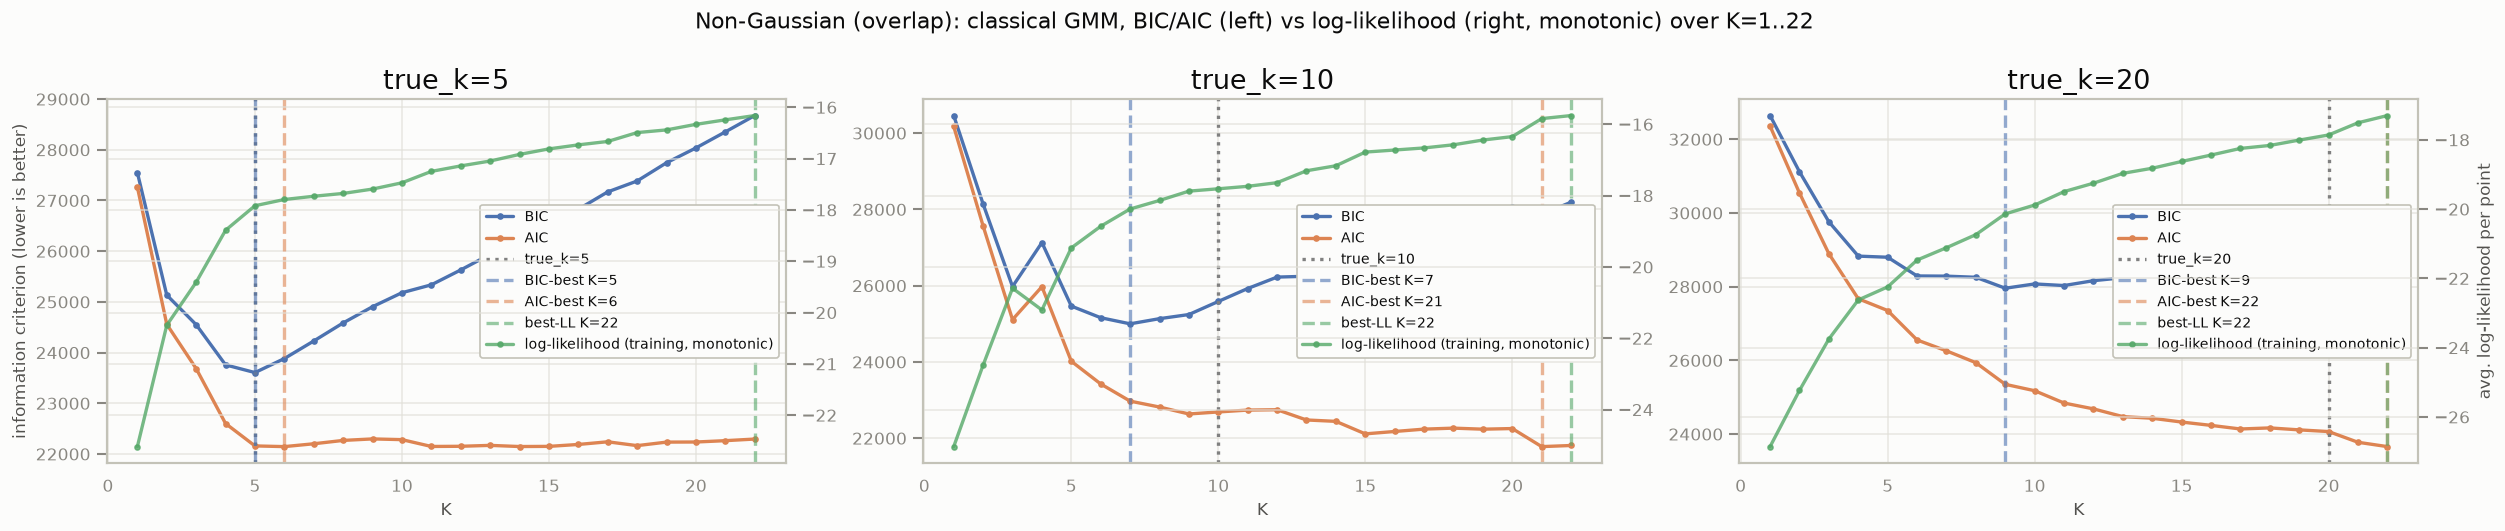

In [ ]:
round_non_gaussian['fig_ic']

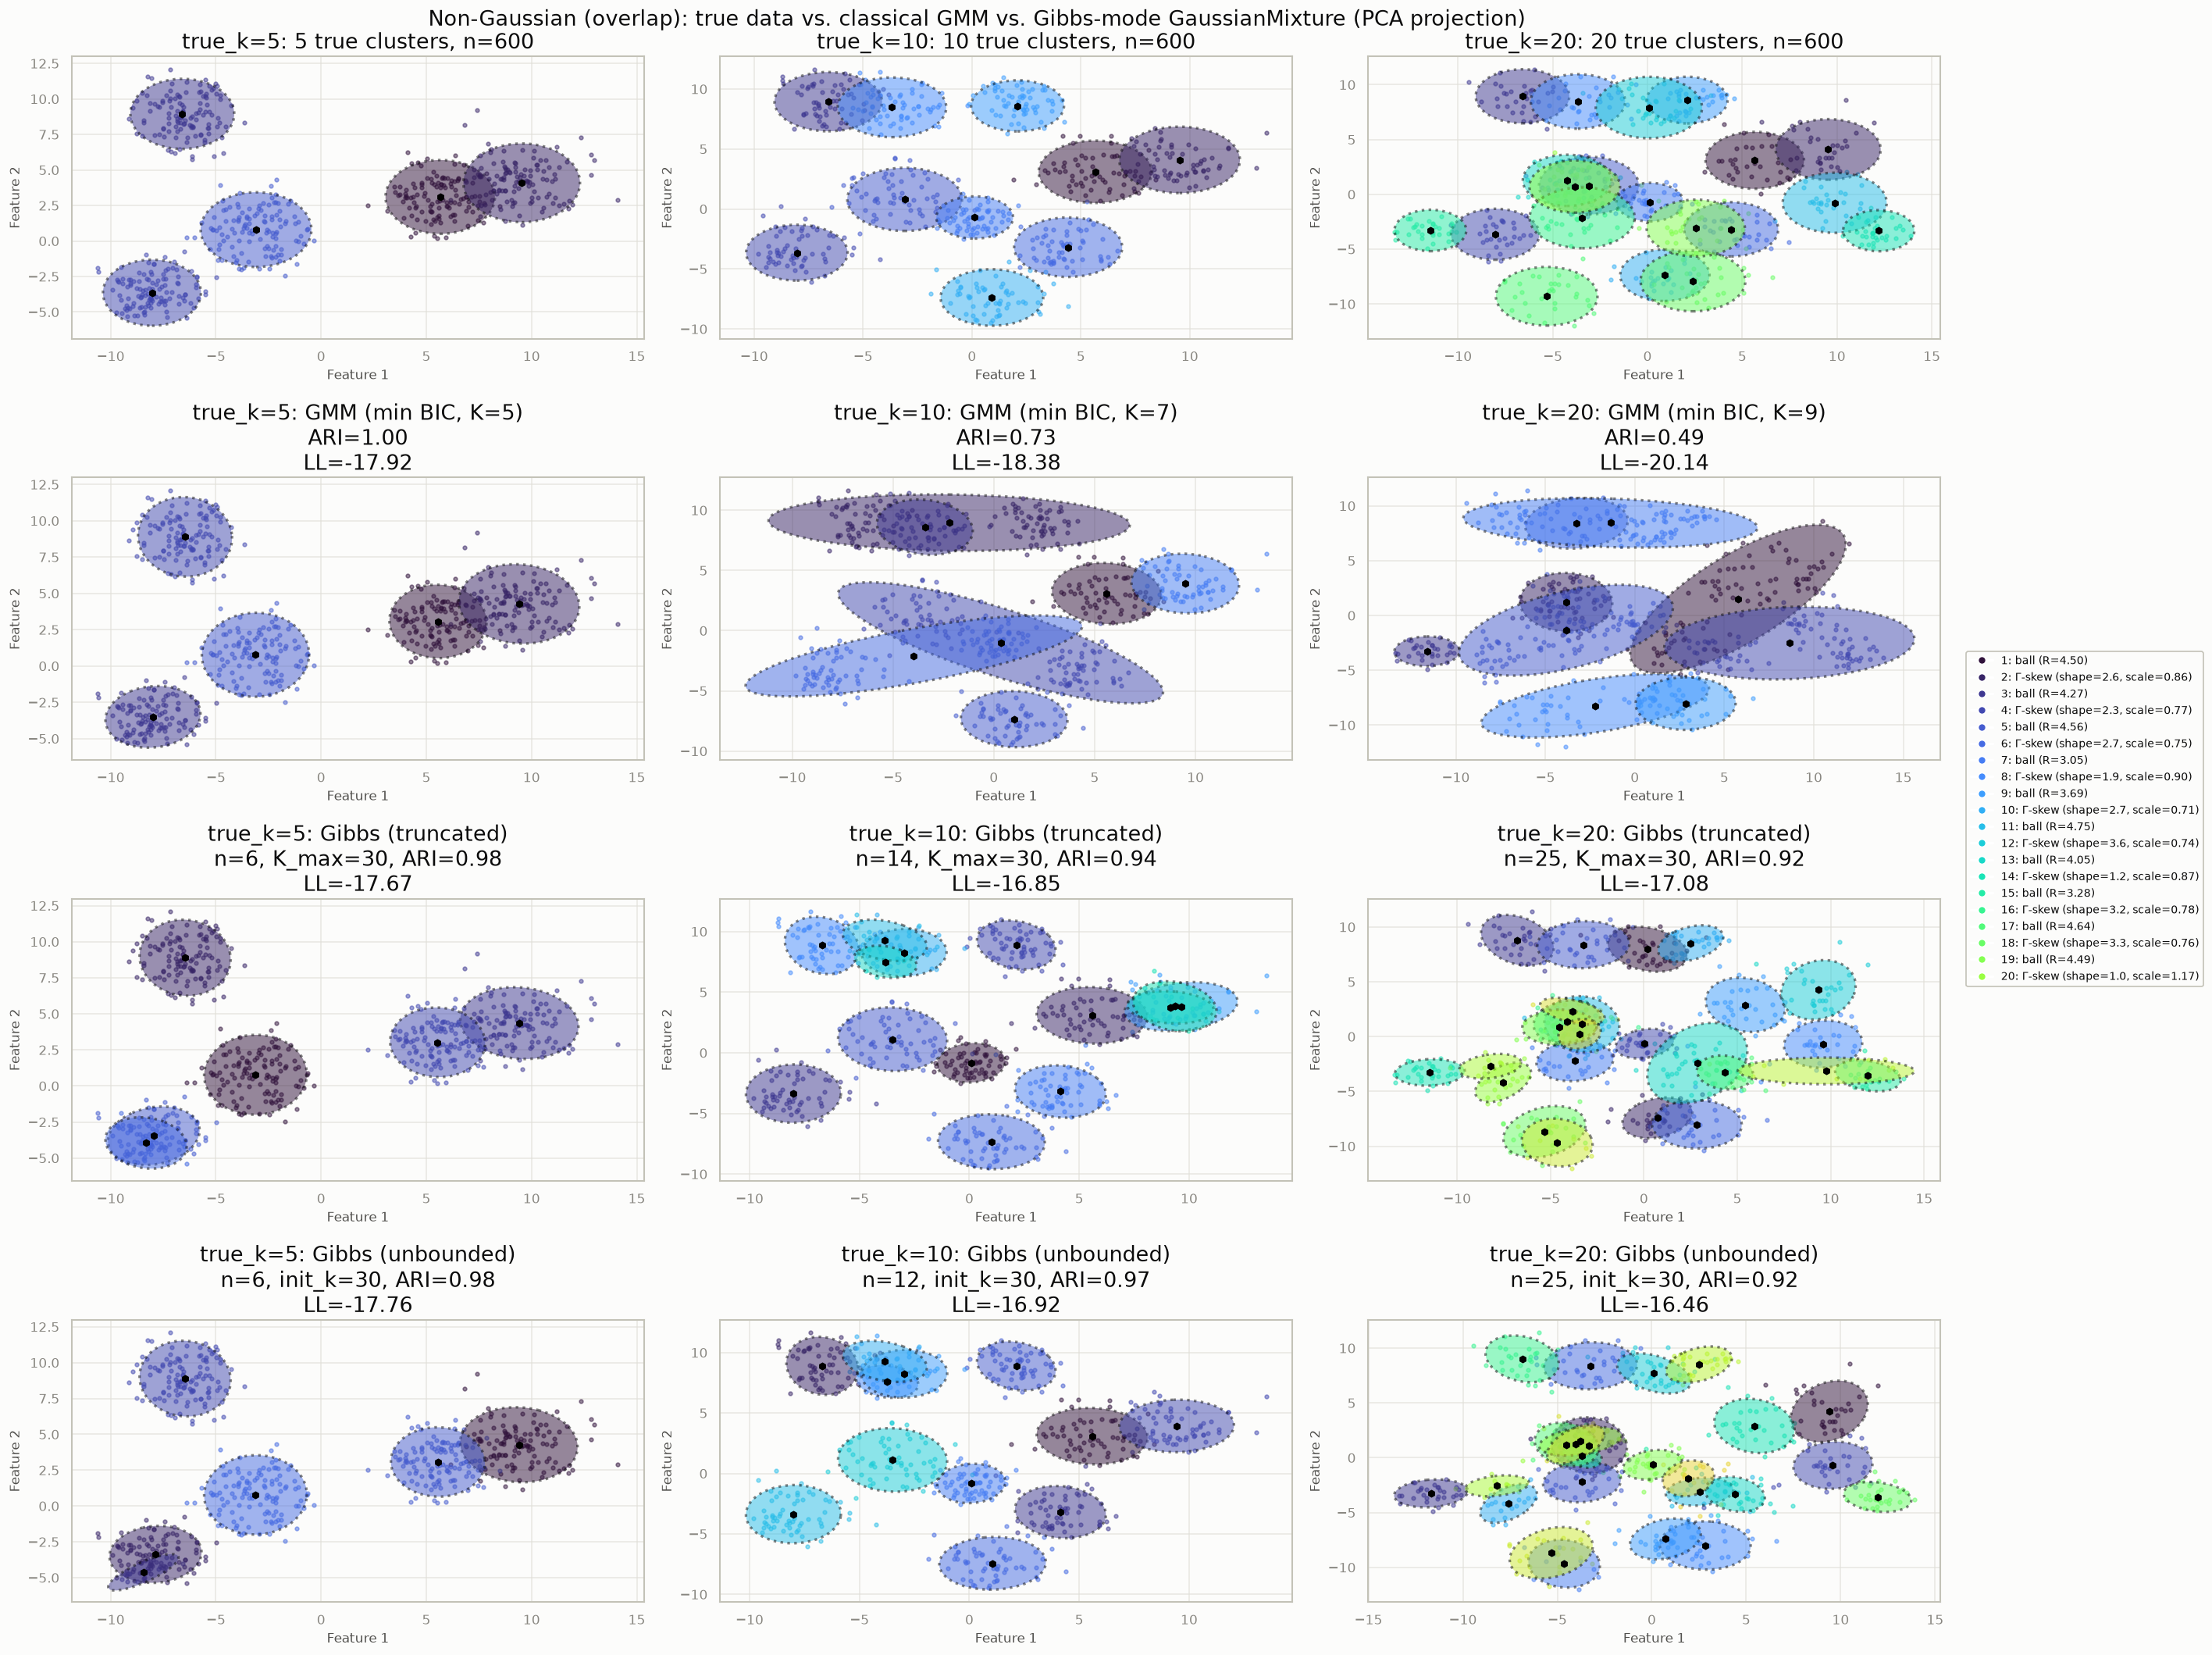

In [ ]:
round_non_gaussian['fig_grid']

## Summary

- A Dirichlet process mixture lets the data decide how many components it supports: the stick-breaking weights $\pi_k = v_k\prod_{j<k}(1-v_j)$ with $v_k\sim\mathrm{Beta}(1,\alpha)$ place more mass on fewer components for small $\alpha$ and spread it over many for large $\alpha$.
- Marginalizing out the weights gives the Chinese Restaurant Process, and with a conjugate NIW base measure Neal's Algorithm 3 resamples each point's assignment using Student-$t$ posterior predictives.
- A Gibbs run is a *trace*, not a convergence curve: the component count rises and falls and then stabilizes; `burn_in` only affects the recorded history, not the fitted parameters.
- Truncated (`max_components=K`) and unbounded (`max_components=None`) samplers share the same occupancy-driven logic and agree when given the same starting partition (`init_k`); remaining differences are a mixing effect.
- Compared with classical EM plus a BIC sweep, Gibbs mode lands at or close to the true cluster count on separated data (a short chain or a small sample can leave a few extra small components), tends to be more variable when clusters overlap, and inherits every shortcoming of the Gaussian assumption on non-Gaussian shapes.

**Next:** [12 -- HDBSCAN](12_hdbscan.ipynb) for a nonparametric alternative that needs no component count and no Gaussian assumption, and [13 -- Model Selection](13_model_selection.ipynb) for the classical BIC/AIC/ICL route.